# ДЗ до теми 12 «Механізм уваги»: машинний переклад німецька → англійська (Europarl, seq2seq + attention)

Студент: Фарід Джафарлі
Курс: Deep Learning for Computer Vision and NLP (GoIT)
Дані: [`Helsinki-NLP/europarl`](https://huggingface.co/datasets/Helsinki-NLP/europarl) (HuggingFace), паралельний корпус стенограм засідань Європарламенту

Мета роботи: навчити модель машинного перекладу для пари мов з Europarl. Модель складається з енкодера (двонаправлений GRU) і декодера з адитивною увагою (Bahdanau), як у практиці теми 12. Після навчання я аналізую криві втрат, візуалізую та інтерпретую ваги уваги і порівнюю переклади з еталонами.

Структура ноутбука і відповідність крокам інструкції та критеріям прийняття:

| Розділ | Крок інструкції | Критерій |
|---|---|---|
| 1. Імпорт бібліотек, відтворюваність, пристрій, налаштування | 1 | код виконується |
| 2. Вибір пари мов | 2 | пара мов з Europarl |
| 3-4. Завантаження (`datasets`), EDA, фільтрація, train / val / test | 3 | дані завантажені й підготовлені |
| 5-6. Токенізація (spaCy), словники, `Dataset` / `DataLoader` | 3 | дані підготовлені |
| 7. Модель: Encoder, Attention, Decoder, Seq2Seq (PyTorch) | 4 | енкодер + декодер з увагою |
| 8. `CrossEntropyLoss`, Adam, функція епохи, цикл навчання | 5-6 | модель навчена |
| 9. Графіки loss / perplexity / BLEU та їх аналіз | 7-8 | графік loss |
| 10. Оцінка на тесті (loss, PPL, BLEU, chrF), greedy vs beam search | 8 | оцінка |
| 11. Приклади перекладів: тестові речення та власні речення | 9 | приклади перекладів |
| 12. Візуалізація уваги + кількісний аналіз уваги | 7-8 | візуалізація уваги з коментарями |
| 13. Сильні / слабкі сторони, ідеї покращення, висновки | 8 | аналіз |

> Архітектура моделі повторює код практичного заняття (туторіал bentrevett «Neural Machine Translation by Jointly Learning to Align and Translate»). Відмінності від коду з лекції пояснені в розділах 5-8: власний словник замість застарілого `torchtext`, маска `<pad>` в увазі, dropout на ембедингах, батчі зі схожою довжиною речень і порівняння train / val loss в однаковому режимі.

## 1. Імпорт бібліотек, відтворюваність і налаштування

In [1]:
import copy
import json
import math
import os
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

import spacy
import datasets
import sacrebleu
from datasets import load_dataset, get_dataset_config_names
from huggingface_hub.utils import logging as hf_logging

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Sampler

datasets.disable_progress_bars()          # no progress bars in the saved notebook
datasets.logging.set_verbosity_error()
hf_logging.set_verbosity_error()          # hides the "unauthenticated requests to the HF Hub" notice

SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Fix python / numpy / torch random generators (torch.manual_seed also seeds MPS and CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')          # Apple Silicon GPU
else:
    DEVICE = torch.device('cpu')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_colwidth', 150)
pd.set_option('display.width', 200)

NOTEBOOK_START = time.time()
print(f'torch {torch.__version__} | datasets {datasets.__version__} | spaCy {spacy.__version__} | '
      f'sacrebleu {sacrebleu.__version__} | device: {DEVICE}')

torch 2.14.0 | datasets 5.0.1 | spaCy 3.8.16 | sacrebleu 2.6.0 | device: mps


Усі гіперпараметри зібрані в одній клітинці, щоб їх було легко змінити. Чому обрано саме такі значення, пояснюю у відповідних розділах нижче.

In [2]:
# ---- data ----
SRC_LANG, TRG_LANG = 'de', 'en'         # translate German -> English
PAIR = 'de-en'                          # config name in Helsinki-NLP/europarl (languages in alphabetical order)
MIN_WORDS, MAX_WORDS = 3, 25            # words per side (fast whitespace pre-filter)
MAX_TOKENS = 30                         # spaCy tokens per side after tokenization (without <sos>/<eos>)
LEN_RATIO = (0.5, 2.0)                  # allowed en/de word-count ratio (drops misaligned pairs)
N_TRAIN, N_VAL, N_TEST = 150_000, 3_000, 3_000
MIN_FREQ = 5                            # a token enters the vocabulary if it occurs >= MIN_FREQ times in train

# ---- model ----
EMB_DIM = 256                           # embedding size (encoder and decoder), as in the lecture
HID_DIM = 512                           # GRU hidden size (encoder per direction and decoder), as in the lecture
DROPOUT = 0.3                           # dropout on embeddings

# ---- training ----
BATCH_SIZE = 128                        # as in the lecture
N_EPOCHS = 8
LR = 1e-3                               # Adam default
CLIP = 1.0                              # gradient clipping (max global norm)
TEACHER_FORCING = 0.5                   # probability of feeding the true previous token (as in the lecture)
PATIENCE = 3                            # early stopping on validation loss
TRAIN_MODEL = True                      # False -> load saved weights + history instead of training (~1 h saved)
RESUME = True                           # continue from saved_models/last_checkpoint.pt if the run was interrupted

# ---- evaluation ----
EVAL_BATCH_SIZE = 256
MAX_OUTPUT_LEN = MAX_TOKENS + 10        # max generated tokens
N_TRAIN_EVAL = 3_000                    # fixed train subset evaluated like validation (fair train/val comparison)
N_BLEU_VAL = 1_000                      # validation sentences for BLEU after every epoch
N_BEAM = 500                            # test sentences for the greedy vs beam-search comparison
BEAM_SIZE = 5

MODEL_DIR = Path('saved_models')
MODEL_DIR.mkdir(exist_ok=True)
BEST_MODEL_PATH = MODEL_DIR / 'seq2seq_attention_de_en_best.pt'
HISTORY_PATH = MODEL_DIR / 'history_de_en.json'
LOG_PATH = MODEL_DIR / 'train_log.txt'
LAST_CKPT_PATH = MODEL_DIR / 'last_checkpoint.pt'   # model + optimizer + history after every epoch

# macOS writes Metal (MPS) driver diagnostics straight to the process stderr (file descriptor 2), bypassing Python.
# On a busy shared GPU there can be dozens of them, so they go to a file; Python warnings/errors stay in the notebook.
NATIVE_STDERR_LOG = MODEL_DIR / 'native_stderr.log'
if DEVICE.type == 'mps':
    os.dup2(os.open(NATIVE_STDERR_LOG, os.O_WRONLY | os.O_CREAT | os.O_TRUNC), 2)

## 2. Вибір пари мов

У наборі `Helsinki-NLP/europarl` кожна конфігурація відповідає окремій парі мов. Назва складається з кодів мов в алфавітному порядку (`de-en`, `en-fr`, …), а напрям перекладу обираємо самі.

In [3]:
configs = get_dataset_config_names('Helsinki-NLP/europarl')
en_pairs = [c for c in configs if 'en' in c.split('-')]
print(f'Конфігурацій (пар мов) у Helsinki-NLP/europarl: {len(configs)}')
print(f'З них з англійською ({len(en_pairs)}):', ', '.join(en_pairs))

Конфігурацій (пар мов) у Helsinki-NLP/europarl: 210
З них з англійською (20): bg-en, cs-en, da-en, de-en, el-en, en-es, en-et, en-fi, en-fr, en-hu, en-it, en-lt, en-lv, en-nl, en-pl, en-pt, en-ro, en-sk, en-sl, en-sv


Я обрав пару німецька → англійська (`de-en`) з таких причин:

- обидві мови підтримуються spaCy (`de_core_news_sm`, `en_core_web_sm`), як рекомендовано в інструкції;
- переклади англійською легко перевіряти вручну;
- у німецькій інший порядок слів: дієслово стоїть у кінці підрядного речення (*…, dass wir das Problem lösen müssen*), є розділені дієслівні конструкції (*ich habe den Bericht gelesen*) і відокремлювані префікси (*ich stimme … zu*). Тому матриця уваги не може бути суто діагональною, і її цікавіше аналізувати;
- практика теми 12 була на цій самій парі (але на Multi30k), тож результати можна порівняти.

## 3. Завантаження даних і розвідувальний аналіз (EDA)

In [4]:
raw = load_dataset('Helsinki-NLP/europarl', PAIR, split='train')   # the only split in this dataset
print(raw)
print(raw.features)
print(raw[1])

Dataset({
    features: ['translation'],
    num_rows: 1961119
})
{'translation': Translation(languages=['de', 'en'])}
{'translation': {'de': 'Ich erkläre die am Freitag, dem 17. Dezember unterbrochene Sitzungsperiode des Europäischen Parlaments für wiederaufgenommen, wünsche Ihnen nochmals alles Gute zum Jahreswechsel und hoffe, daß Sie schöne Ferien hatten.', 'en': 'I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999, and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period.'}}


Кожен запис має вигляд словника `{'translation': {'de': …, 'en': …}}`. Для зручності «розплющую» його в таблицю pandas з колонками `de` / `en`.

In [5]:
df_all = (raw.flatten()
             .rename_columns({f'translation.{SRC_LANG}': SRC_LANG, f'translation.{TRG_LANG}': TRG_LANG})
             .to_pandas())
df_all['de_words'] = df_all['de'].str.split().str.len()
df_all['en_words'] = df_all['en'].str.split().str.len()

print(f'Усього пар речень: {len(df_all):,}')
display(df_all.sample(5, random_state=SEED)[['de', 'en']])

Усього пар речень: 1,961,119


,de,en
919577,"Nun versucht sie unter dem Vorwand technischer Änderungen, die Interventionsregelung für den Schweinefleischsektor abzuschaffen, was in Verbindung...","Now, under the guise of technical amendments, it is trying to intervene in the pork market, which in combination with the elimination of maize sub..."
1161866,"Alle Mitgliedstaaten müssen in diese Bereiche investieren, und sie müssen das sofort tun, sonst erreichen wir nicht die Ziele unseres eigenen Klim...","All the Member States need to invest in these areas, and they need to do so right away, otherwise we will not reach the targets of our own climate..."
890020,"Ich glaube, wenn wir uns gegenseitig Gehör schenken, wird es uns gelingen, die europäische Weinproduktion auf dem Weltmarkt zu halten.",I think that if we listen to each other we will be able to retain European wine production on the world stage.
1445609,"Was Libyen angeht, haben uns die Entwicklungen in Libyen wieder einmal daran erinnert, dass wir nicht zu viel von der sogenannten Gemeinsamen Auße...","Turning to Libya, developments in Libya have reminded us once again that we should not expect too much from the so-called EU Common Foreign and Se..."
1068859,Die UN sind die internationale Organisation mit den besten Voraussetzungen für eine dauerhafte Lösung im Nahostkonflikt und den Umgang mit dieser ...,The United Nations is the international organisation which is best equipped to bring about a lasting settlement of the conflict in the Middle East...


In [6]:
stats = df_all[['de_words', 'en_words']].describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).T
display(stats.round(1))

n_dup = df_all.duplicated(['de', 'en']).sum()
share_long = ((df_all['de_words'] > MAX_WORDS) | (df_all['en_words'] > MAX_WORDS)).mean()
print(f'Точних дублікатів пар: {n_dup:,} ({n_dup / len(df_all):.1%})')
print(f'Пар, де хоча б одна сторона довша за {MAX_WORDS} слів: {share_long:.1%}')
print(f'Порожніх рядків: de = {(df_all["de"].str.strip() == "").sum()}, en = {(df_all["en"].str.strip() == "").sum()}')

# old vs new German spelling in the corpus (1996 reform): the model has to learn both
n_dass_old = df_all['de'].str.contains(r'(?:^|[\s,;])[dD]aß[\s,;.]', regex=True).sum()
n_dass_new = df_all['de'].str.contains(r'(?:^|[\s,;])[dD]ass[\s,;.]', regex=True).sum()
print(f'Речень з "daß" (стара орфографія): {n_dass_old:,}; з "dass" (нова): {n_dass_new:,}')

print('\nНайчастіші німецькі речення (кандидати на дублікати):')
display(df_all['de'].value_counts().head(8).rename('кількість').to_frame())

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
de_words,1961119.0,23.3,14.0,1.0,8.0,13.0,21.0,30.0,41.0,49.0,68.0,426.0
en_words,1961119.0,25.0,15.1,1.0,9.0,14.0,22.0,33.0,44.0,53.0,73.0,668.0


Точних дублікатів пар: 44,171 (2.3%)
Пар, де хоча б одна сторона довша за 25 слів: 43.4%
Порожніх рядків: de = 0, en = 0


Речень з "daß" (стара орфографія): 130,792; з "dass" (нова): 333,121

Найчастіші німецькі речення (кандидати на дублікати):


,кількість
de,
.,4345
Die Aussprache ist geschlossen.,3526
(Beifall),2857
.,906
Die Abstimmung findet morgen um 12.00 Uhr statt.,885
Vielen Dank.,680
. – Herr Präsident!,551
Herr Präsident!,487


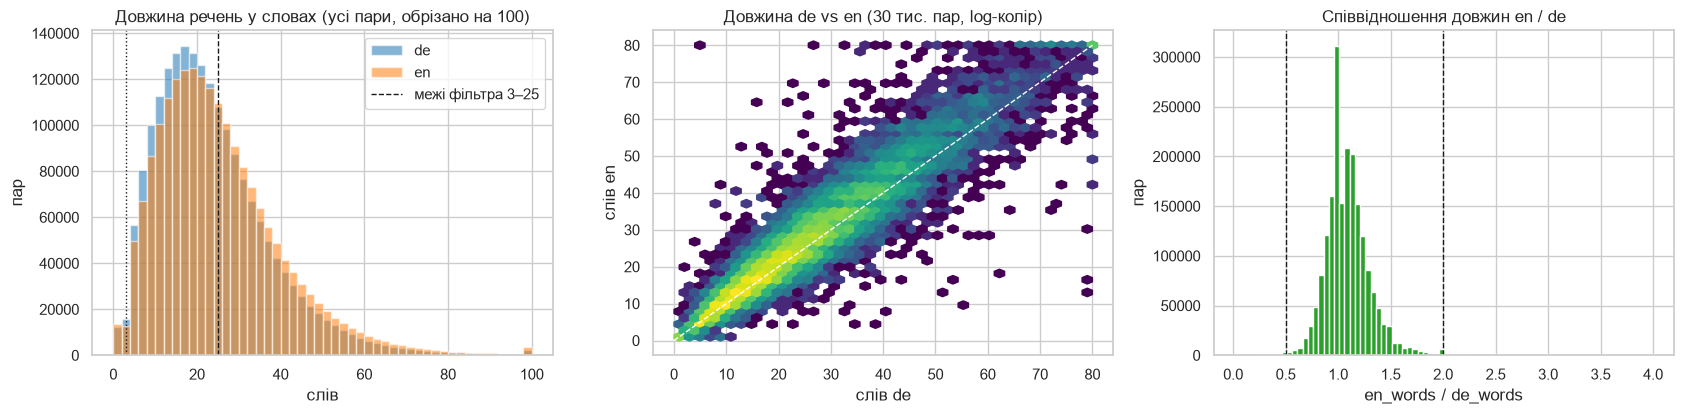

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))

bins = np.arange(0, 101, 2)
for lang, color in [('de', 'tab:blue'), ('en', 'tab:orange')]:
    axes[0].hist(df_all[f'{lang}_words'].clip(upper=100), bins=bins, alpha=0.55, label=lang, color=color)
axes[0].axvline(MIN_WORDS, color='k', ls=':', lw=1)
axes[0].axvline(MAX_WORDS, color='k', ls='--', lw=1, label=f'межі фільтра {MIN_WORDS}–{MAX_WORDS}')
axes[0].set(title='Довжина речень у словах (усі пари, обрізано на 100)', xlabel='слів', ylabel='пар')
axes[0].legend()

sample = df_all.sample(30_000, random_state=SEED)
axes[1].hexbin(sample['de_words'].clip(upper=80), sample['en_words'].clip(upper=80), gridsize=40,
               cmap='viridis', bins='log', mincnt=1)
axes[1].plot([0, 80], [0, 80], 'w--', lw=1)
axes[1].set(title='Довжина de vs en (30 тис. пар, log-колір)', xlabel='слів de', ylabel='слів en')

ratio = (df_all['en_words'] / df_all['de_words'].clip(lower=1)).clip(upper=4)
axes[2].hist(ratio, bins=80, color='tab:green')
for r in LEN_RATIO:
    axes[2].axvline(r, color='k', ls='--', lw=1)
axes[2].set(title='Співвідношення довжин en / de', xlabel='en_words / de_words', ylabel='пар')
plt.tight_layout()
plt.show()

Що видно з EDA:

- Europarl великий (≈ 1.96 млн пар), а речення в ньому довгі й офіційні: медіана ≈ 21-22 слова, 10 % пар довші за 40 слів. Я навчаю RNN-модель з увагою локально за ~1 год, і для неї це забагато. Час епохи росте лінійно з довжиною речення, а на довгих реченнях RNN перекладає найгірше.
- Англійські речення в середньому трохи довші за німецькі, бо в німецькій є складні слова (*Haushaltsordnung* = *financial regulation*). Довжини сильно корелюють: хмарка точок лежить уздовж діагоналі.
- Є дублікати (службові фрази на кшталт *(Beifall)* / *(Applause)*, «Die Aussprache ist geschlossen.») і пари з нетиповим співвідношенням довжин, тобто помилки вирівнювання речень.
- У німецькій частині трапляються обидві орфографії: *daß* (до реформи 1996 р., ≈ 131 тис. речень) і *dass* (≈ 333 тис.), тож модель має вивчити обидва написання.

Звідси план підготовки: обмежити довжину, прибрати дублікати й підозрілі пари і взяти випадкову підвибірку.

## 4. Фільтрація, підвибірка, розбиття train / validation / test

Фільтри (результат кожного кроку є в таблиці нижче):

1. без точних дублікатів пар;
2. 3-25 слів з обох боків (дешевий попередній фільтр за пробілами);
3. співвідношення довжин en/de у межах 0.5-2, щоб відкинути погано вирівняні пари;
4. унікальне німецьке речення (без урахування регістру), щоб те саме джерело не потрапило одночасно в train і test;
5. після токенізації spaCy не більше 30 токенів з кожного боку.

Потім перемішую пари з фіксованим seed і беру 150 тис. пар для train та по 3 тис. для validation і test (train ≈ 7.6 % корпусу). Зріз на кшталт `train[:10%]` узяв би перші засідання, які йдуть хронологічно поруч, а не випадкову вибірку. У наборі є лише спліт `train`, тому розбиття роблю сам.

In [8]:
steps = [('усі пари', len(df_all))]
d = df_all.drop_duplicates(['de', 'en'])
steps.append(('без дублікатів пар', len(d)))
d = d[d['de_words'].between(MIN_WORDS, MAX_WORDS) & d['en_words'].between(MIN_WORDS, MAX_WORDS)]
steps.append((f'{MIN_WORDS}–{MAX_WORDS} слів з обох боків', len(d)))
d = d[(d['en_words'] / d['de_words']).between(*LEN_RATIO)]
steps.append((f'співвідношення довжин {LEN_RATIO[0]}–{LEN_RATIO[1]}', len(d)))
d = d.assign(src_key=d['de'].str.lower().str.strip()).drop_duplicates('src_key')
steps.append(('унікальне німецьке речення', len(d)))

# shuffle with a fixed seed and keep a pool slightly larger than needed (some pairs drop after tokenization)
n_needed = N_TRAIN + N_VAL + N_TEST
pool = d.sample(frac=1.0, random_state=SEED).iloc[:int(n_needed * 1.03)].reset_index(drop=True)
del d

### Токенізація spaCy

Використовую правилові токенізатори spaCy `spacy.blank('de')` / `spacy.blank('en')`. Це той самий токенізатор, що й у пакетах `de_core_news_sm` / `en_core_web_sm` з лекції (у `*_core_*_sm` він береться з мовних налаштувань). Тегер, парсер і NER для перекладу не потрібні, а без них токенізація працює значно швидше і не треба завантажувати моделі. Як і в лекції, переводжу токени в нижній регістр і додаю `<sos>` / `<eos>` під час нумерації.

In [9]:
de_nlp = spacy.blank(SRC_LANG)
en_nlp = spacy.blank(TRG_LANG)


def tokenize_texts(texts, nlp, lower=True):
    """spaCy rule-based tokenization of many texts; whitespace tokens are dropped."""
    out = []
    for doc in nlp.tokenizer.pipe(texts, batch_size=2_000):
        out.append([t.text.lower() if lower else t.text for t in doc if not t.is_space])
    return out


t0 = time.time()
pool['de_tok'] = tokenize_texts(pool['de'].tolist(), de_nlp)
pool['en_tok'] = tokenize_texts(pool['en'].tolist(), en_nlp)
pool['de_len'] = pool['de_tok'].str.len()
pool['en_len'] = pool['en_tok'].str.len()
print(f'Токенізовано {len(pool):,} пар за {time.time() - t0:.0f} с')

pool = pool[(pool['de_len'] <= MAX_TOKENS) & (pool['en_len'] <= MAX_TOKENS)].reset_index(drop=True)
steps.append((f'≤ {MAX_TOKENS} токенів spaCy (у пулі {int(n_needed * 1.03):,} випадкових пар)', len(pool)))

cols = ['de', 'en', 'de_tok', 'en_tok', 'de_len', 'en_len']
test_df = pool.iloc[:N_TEST][cols].reset_index(drop=True)
valid_df = pool.iloc[N_TEST:N_TEST + N_VAL][cols].reset_index(drop=True)
train_df = pool.iloc[N_TEST + N_VAL:N_TEST + N_VAL + N_TRAIN][cols].reset_index(drop=True)
steps += [('train', len(train_df)), ('validation', len(valid_df)), ('test', len(test_df))]

display(pd.DataFrame(steps, columns=['крок', 'пар']).style.format({'пар': '{:,}'}).hide(axis='index'))
print(f'Train становить {len(train_df) / len(df_all):.1%} усього корпусу')
print('\nПриклад токенізації:')
print(train_df.loc[0, 'de'], '\n ->', train_df.loc[0, 'de_tok'])
print(train_df.loc[0, 'en'], '\n ->', train_df.loc[0, 'en_tok'])

Токенізовано 160,680 пар за 19 с


крок,пар
усі пари,"1,961,119"
без дублікатів пар,"1,916,948"
3–25 слів з обох боків,"1,062,624"
співвідношення довжин 0.5–2.0,"1,055,871"
унікальне німецьке речення,"1,047,200"
"≤ 30 токенів spaCy (у пулі 160,680 випадкових пар)","159,869"
train,"150,000"
validation,"3,000"
test,"3,000"


Train становить 7.6% усього корпусу

Приклад токенізації:
Einer von vielen Beweisen für die untergeordnete Rolle der Frauen ist die Gewalt von Männern gegenüber Frauen. 
 -> ['einer', 'von', 'vielen', 'beweisen', 'für', 'die', 'untergeordnete', 'rolle', 'der', 'frauen', 'ist', 'die', 'gewalt', 'von', 'männern', 'gegenüber', 'frauen', '.']
Part of the evidence of women’s subordination is male violence against women. 
 -> ['part', 'of', 'the', 'evidence', 'of', 'women', '’s', 'subordination', 'is', 'male', 'violence', 'against', 'women', '.']


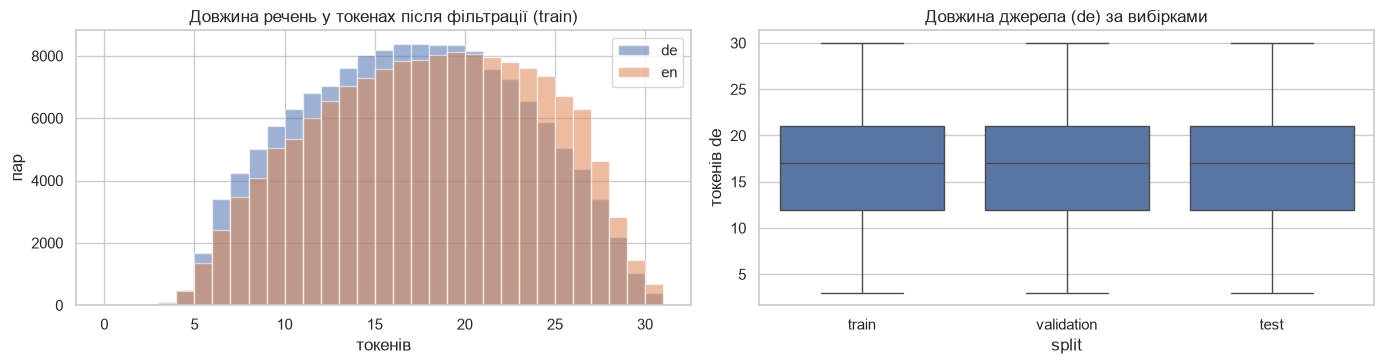

,train,validation,test
середня довжина de,16.69,16.60,16.77
середня довжина en,17.60,17.55,17.66


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
bins = np.arange(0, MAX_TOKENS + 2)
axes[0].hist(train_df['de_len'], bins=bins, alpha=0.55, label='de')
axes[0].hist(train_df['en_len'], bins=bins, alpha=0.55, label='en')
axes[0].set(title='Довжина речень у токенах після фільтрації (train)', xlabel='токенів', ylabel='пар')
axes[0].legend()
split_len = pd.DataFrame({'split': ['train'] * len(train_df) + ['validation'] * len(valid_df) + ['test'] * len(test_df),
                          'de_len': pd.concat([train_df['de_len'], valid_df['de_len'], test_df['de_len']]).values})
sns.boxplot(data=split_len, x='split', y='de_len', ax=axes[1])
axes[1].set(title='Довжина джерела (de) за вибірками', ylabel='токенів de')
plt.tight_layout()
plt.show()
display(pd.DataFrame({s: [x['de_len'].mean(), x['en_len'].mean()] for s, x in
                      [('train', train_df), ('validation', valid_df), ('test', test_df)]},
                     index=['середня довжина de', 'середня довжина en']).round(2))

Після фільтрації речення мають 3-30 токенів (у середньому ≈ 17). Розподіли довжин у train / validation / test однакові, бо всі три вибірки взяті з одного перемішаного пулу.

## 5. Словники та нумерація

Бібліотека `torchtext` з лекції застаріла: розробку припинено у 2024 р., а остання версія сумісна лише з torch 2.3. Тому словник я будую сам: `Counter` по токенах лише з train, поріг `min_freq`, спецтокени `<unk>`, `<pad>`, `<sos>`, `<eos>` на тих самих індексах 0-3, що й у лекції. Інтерфейс (`lookup_indices` / `lookup_tokens`) повторює `torchtext.vocab`, щоб код був схожий на лекційний.

`min_freq = 5` (а не 2, як на Multi30k), бо в Europarl набагато більше рідкісних слів: прізвища, німецькі складні слова. Від розміру англійського словника напряму залежать розмір вихідного шару `fc_out` (це найбільший шар моделі) і час кожного кроку декодера.

In [11]:
UNK, PAD, SOS, EOS = '<unk>', '<pad>', '<sos>', '<eos>'
SPECIALS = [UNK, PAD, SOS, EOS]


class Vocab:
    """Minimal replacement of torchtext.vocab.Vocab: token <-> index with a default <unk> index."""

    def __init__(self, token_lists, min_freq, specials):
        self.freqs = Counter(tok for tokens in token_lists for tok in tokens)
        words = [w for w, c in self.freqs.items() if c >= min_freq and w not in specials]
        words.sort(key=lambda w: (-self.freqs[w], w))           # frequent first, ties alphabetically
        self.itos = list(specials) + words
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.default_index = self.stoi[UNK]                     # OOV -> <unk>

    def __len__(self):
        return len(self.itos)

    def __getitem__(self, token):
        return self.stoi.get(token, self.default_index)

    def lookup_indices(self, tokens):
        return [self.stoi.get(t, self.default_index) for t in tokens]

    def lookup_tokens(self, indices):
        return [self.itos[i] for i in indices]


de_vocab = Vocab(train_df['de_tok'], MIN_FREQ, SPECIALS)
en_vocab = Vocab(train_df['en_tok'], MIN_FREQ, SPECIALS)
assert de_vocab[UNK] == en_vocab[UNK] and de_vocab[PAD] == en_vocab[PAD]
UNK_IDX, PAD_IDX, SOS_IDX, EOS_IDX = (en_vocab[t] for t in SPECIALS)
print(f'<unk>={UNK_IDX}, <pad>={PAD_IDX}, <sos>={SOS_IDX}, <eos>={EOS_IDX}')


def vocab_report(vocab, lang):
    """Vocabulary size and share of OOV (-> <unk>) tokens per split."""
    row = {'мова': lang, 'унікальних токенів у train': len(vocab.freqs), 'розмір словника': len(vocab)}
    for name, df in [('train', train_df), ('validation', valid_df), ('test', test_df)]:
        tokens = [t for s in df[f'{lang}_tok'] for t in s]
        row[f'<unk> у {name}, %'] = 100 * np.mean([t not in vocab.stoi for t in tokens])
    return row


display(pd.DataFrame([vocab_report(de_vocab, 'de'), vocab_report(en_vocab, 'en')]).round(2).set_index('мова'))
print('Найчастіші токени de:', de_vocab.itos[4:24])
print('Найчастіші токени en:', en_vocab.itos[4:24])

oov_de = Counter(t for s in valid_df['de_tok'] for t in s if t not in de_vocab.stoi)
print('\nНайчастіші OOV-токени de у validation:', [w for w, _ in oov_de.most_common(15)])

<unk>=0, <pad>=1, <sos>=2, <eos>=3


,унікальних токенів у train,розмір словника,"<unk> у train, %","<unk> у validation, %","<unk> у test, %"
мова,,,,,
de,77761,18250,3.57,4.07,3.86
en,30741,11956,1.19,1.40,1.36


Найчастіші токени de: ['.', ',', 'die', 'der', 'und', 'in', 'wir', 'ist', 'ich', 'zu', 'das', 'den', 'es', 'für', 'von', 'nicht', 'eine', 'werden', 'auf', 'dass']
Найчастіші токени en: ['the', '.', ',', 'to', 'of', 'and', 'in', 'is', 'that', 'a', 'we', 'this', 'i', 'for', 'it', 'be', 'on', 'not', 'are', 'have']

Найчастіші OOV-токени de у validation: ['verankerte', 'gewohnheit', 'berufstätiger', 'befürwortern', 'mörderischen', 'gesundheitsproblemen', 'wirtschaftssysteme', 'forschungstätigkeiten', 'erstattungen', 'ranking', 'mfr', 'beratungsgremien', 'wechselkurs', 'karikaturen', 'deflation']


Словник покриває ~96 % німецьких і ~98-99 % англійських токенів нових речень (точні значення в таблиці). У німецькій помітно більше `<unk>`. Серед OOV-токенів переважають складні слова (*gesundheitsproblemen*, *forschungstätigkeiten*, *beratungsgremien*) і рідкісні відмінкові форми (*befürwortern*, *mörderischen*). Це звичайна проблема словникових (word-level) моделей, її розв'язують субсловні токенізатори (BPE / SentencePiece).

In [12]:
def numericalize(tokens, vocab):
    """tokens -> [<sos>] + ids + [<eos>] as a LongTensor."""
    return torch.tensor(vocab.lookup_indices([SOS] + tokens + [EOS]), dtype=torch.long)


class TranslationDataset(Dataset):
    """Stores numericalized pairs; items look like in the lecture: {'de_ids': tensor, 'en_ids': tensor}."""

    def __init__(self, df):
        self.de_ids = [numericalize(t, de_vocab) for t in df['de_tok']]
        self.en_ids = [numericalize(t, en_vocab) for t in df['en_tok']]

    def __len__(self):
        return len(self.de_ids)

    def __getitem__(self, idx):
        return {'de_ids': self.de_ids[idx], 'en_ids': self.en_ids[idx]}


train_data = TranslationDataset(train_df)
valid_data = TranslationDataset(valid_df)
test_data = TranslationDataset(test_df)
train_eval_data = torch.utils.data.Subset(train_data, range(N_TRAIN_EVAL))   # fixed train subset for evaluation

print(train_df.loc[0, 'de_tok'])
print(train_data[0]['de_ids'])
print(de_vocab.lookup_tokens(train_data[0]['de_ids'].tolist()))

['einer', 'von', 'vielen', 'beweisen', 'für', 'die', 'untergeordnete', 'rolle', 'der', 'frauen', 'ist', 'die', 'gewalt', 'von', 'männern', 'gegenüber', 'frauen', '.']
tensor([    2,    54,    18,   249,  2393,    17,     6, 11369,   245,     7,
          242,    11,     6,   540,    18,  1961,   300,   242,     4,     3])
['<sos>', 'einer', 'von', 'vielen', 'beweisen', 'für', 'die', 'untergeordnete', 'rolle', 'der', 'frauen', 'ist', 'die', 'gewalt', 'von', 'männern', 'gegenüber', 'frauen', '.', '<eos>']


## 6. DataLoader: паддинг і батчі зі схожою довжиною

`collate_fn` такий самий, як у лекції: `pad_sequence` доповнює речення батчу токеном `<pad>` до найдовшого, батч має форму `(seq_len, batch_size)` (`batch_first=False`, як очікує `nn.GRU`).

Додатково використовую bucket-семплер. Індекси перемішуються і діляться на великі блоки (50 батчів). Усередині блоку вони сортуються за довжиною джерела й нарізаються на батчі, а порядок батчів знову перемішується. У батч потрапляють речення схожої довжини, паддингу майже немає, і епоха проходить швидше, бо рекурентна мережа обробляє кожен крок, зокрема й `<pad>`. Випадковість між епохами зберігається.

In [13]:
def get_collate_fn(pad_index):
    def collate_fn(batch):
        batch_de_ids = [example['de_ids'] for example in batch]
        batch_en_ids = [example['en_ids'] for example in batch]
        return {'de_ids': nn.utils.rnn.pad_sequence(batch_de_ids, padding_value=pad_index),   # (src_len, B)
                'en_ids': nn.utils.rnn.pad_sequence(batch_en_ids, padding_value=pad_index)}   # (trg_len, B)
    return collate_fn


class BucketBatchSampler(Sampler):
    """Shuffled batches of similar-length sentences (less padding -> faster RNN epochs)."""

    def __init__(self, lengths, batch_size, bucket_batches=50, seed=SEED):
        self.lengths = np.asarray(lengths)
        self.batch_size = batch_size
        self.chunk = batch_size * bucket_batches
        self.rng = np.random.default_rng(seed)

    def __iter__(self):
        idx = self.rng.permutation(len(self.lengths))
        batches = []
        for start in range(0, len(idx), self.chunk):
            chunk = idx[start:start + self.chunk]
            chunk = chunk[np.argsort(self.lengths[chunk], kind='stable')]
            batches += [chunk[i:i + self.batch_size].tolist() for i in range(0, len(chunk), self.batch_size)]
        for b in self.rng.permutation(len(batches)):
            yield batches[b]

    def __len__(self):
        return math.ceil(len(self.lengths) / self.batch_size)


collate_fn = get_collate_fn(PAD_IDX)
train_loader = DataLoader(train_data, collate_fn=collate_fn,
                          batch_sampler=BucketBatchSampler(train_df['de_len'], BATCH_SIZE))
valid_loader = DataLoader(valid_data, batch_size=EVAL_BATCH_SIZE, collate_fn=collate_fn)
test_loader = DataLoader(test_data, batch_size=EVAL_BATCH_SIZE, collate_fn=collate_fn)
train_eval_loader = DataLoader(train_eval_data, batch_size=EVAL_BATCH_SIZE, collate_fn=collate_fn)


def padding_share(loader):
    real = total = 0
    for batch in loader:
        src = batch['de_ids']
        real += (src != PAD_IDX).sum().item()
        total += src.numel()
    return 1 - real / total


random_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
print(f'Батчів за епоху: {len(train_loader)}')
print(f'Частка <pad> у джерелі: звичайне перемішування {padding_share(random_loader):.1%} -> '
      f'bucket-семплер {padding_share(train_loader):.1%}')

batch = next(iter(train_loader))
print('de_ids:', tuple(batch['de_ids'].shape), '| en_ids:', tuple(batch['en_ids'].shape), '| перший рядок = <sos>:',
      bool((batch['de_ids'][0] == SOS_IDX).all()))

Батчів за епоху: 1172


Частка <pad> у джерелі: звичайне перемішування 39.6% -> bucket-семплер 1.5%
de_ids: (16, 128) | en_ids: (29, 128) | перший рядок = <sos>: True


## 7. Модель: енкодер, увага, декодер, Seq2Seq

Архітектура така сама, як у практиці теми 12 (Bahdanau et al., 2015):

- Енкодер (`Encoder`) складається з ембедингу і двонаправленого GRU. Для кожного вхідного токена він повертає стан `[→h_s ; ←h_s]` розміру `2·HID_DIM`, тобто представлення слова з урахуванням лівого і правого контексту. Початковий стан декодера дорівнює `tanh(Linear([→h_last ; ←h_first]))`.
- Увага (`Attention`) адитивна. Для попереднього стану декодера `s_{t−1}` і кожного стану енкодера `h_s` вона рахує «енергію» `e_{t,s} = vᵀ·tanh(W·[s_{t−1}; h_s])`, а потім `α_{t,·} = softmax(e_{t,·})`. Зміна відносно лекції: позиції `<pad>` маскуються (`masked_fill(-1e10)` до softmax). Без маски короткі речення в батчі віддавали б частину уваги паддингу.
- Декодер (`Decoder`) за один крок виконує таку послідовність: ембединг попереднього слова → ваги уваги → контекстний вектор `c_t = Σ_s α_{t,s}·h_s` (`torch.bmm`) → `GRU([emb; c_t])` → `fc_out([s_t; c_t; emb])` → логіти по словнику англійської.
- `Seq2Seq` один раз запускає енкодер, а далі в циклі робить кроки декодера з teacher forcing: з імовірністю `TEACHER_FORCING` на вхід подається правильне попереднє слово, інакше власне передбачення моделі (`argmax`).

Друга зміна: dropout на ембедингах. Він є в оригінальному туторіалі bentrevett і у виведенні моделі на слайді, але в лекційному коді його немає.

In [14]:
class Encoder(nn.Module):
    def __init__(self, input_dim, embedding_dim, encoder_hidden_dim, decoder_hidden_dim, dropout):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, embedding_dim)
        self.rnn = nn.GRU(embedding_dim, encoder_hidden_dim, bidirectional=True)
        self.fc = nn.Linear(encoder_hidden_dim * 2, decoder_hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        # src: (src_len, B)
        embedded = self.dropout(self.embedding(src))            # (src_len, B, emb)
        outputs, hidden = self.rnn(embedded)
        # outputs: (src_len, B, 2*enc_hid) - states of every step, [forward ; backward]
        # hidden:  (2, B, enc_hid) - hidden[-2] = last forward state, hidden[-1] = last backward state
        hidden = torch.tanh(self.fc(torch.cat((hidden[-2], hidden[-1]), dim=1)))   # (B, dec_hid)
        return outputs, hidden

In [15]:
class Attention(nn.Module):
    """Additive (Bahdanau) attention with a padding mask."""

    def __init__(self, encoder_hidden_dim, decoder_hidden_dim):
        super().__init__()
        self.attn_fc = nn.Linear(encoder_hidden_dim * 2 + decoder_hidden_dim, decoder_hidden_dim)
        self.v_fc = nn.Linear(decoder_hidden_dim, 1, bias=False)

    def forward(self, hidden, encoder_outputs, mask):
        # hidden: (B, dec_hid) - previous decoder state s_{t-1}
        # encoder_outputs: (src_len, B, 2*enc_hid); mask: (B, src_len), True = real token
        src_len = encoder_outputs.shape[0]
        hidden = hidden.unsqueeze(1).repeat(1, src_len, 1)                   # (B, src_len, dec_hid)
        encoder_outputs = encoder_outputs.permute(1, 0, 2)                    # (B, src_len, 2*enc_hid)
        energy = torch.tanh(self.attn_fc(torch.cat((hidden, encoder_outputs), dim=2)))   # (B, src_len, dec_hid)
        attention = self.v_fc(energy).squeeze(2)                              # (B, src_len) - "energy" per token
        attention = attention.masked_fill(~mask, -1e10)                       # <pad> -> weight 0 after softmax
        return torch.softmax(attention, dim=1)                                # (B, src_len), each row sums to 1

In [16]:
class Decoder(nn.Module):
    def __init__(self, output_dim, embedding_dim, encoder_hidden_dim, decoder_hidden_dim, attention, dropout):
        super().__init__()
        self.output_dim = output_dim
        self.attention = attention
        self.embedding = nn.Embedding(output_dim, embedding_dim)
        self.rnn = nn.GRU(encoder_hidden_dim * 2 + embedding_dim, decoder_hidden_dim)
        self.fc_out = nn.Linear(encoder_hidden_dim * 2 + decoder_hidden_dim + embedding_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input, hidden, encoder_outputs, mask):
        # input: (B,) previous target token; hidden: (B, dec_hid); encoder_outputs: (src_len, B, 2*enc_hid)
        embedded = self.dropout(self.embedding(input.unsqueeze(0)))          # (1, B, emb)
        a = self.attention(hidden, encoder_outputs, mask).unsqueeze(1)      # (B, 1, src_len)
        weighted = torch.bmm(a, encoder_outputs.permute(1, 0, 2))            # (B, 1, 2*enc_hid) - context vector c_t
        weighted = weighted.permute(1, 0, 2)                                 # (1, B, 2*enc_hid)
        rnn_input = torch.cat((embedded, weighted), dim=2)                   # (1, B, 2*enc_hid + emb)
        output, hidden = self.rnn(rnn_input, hidden.unsqueeze(0))            # both (1, B, dec_hid); output == hidden
        prediction = self.fc_out(torch.cat((output.squeeze(0), weighted.squeeze(0), embedded.squeeze(0)), dim=1))
        return prediction, hidden.squeeze(0), a.squeeze(1)                   # (B, V), (B, dec_hid), (B, src_len)

In [17]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder, src_pad_index):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_index = src_pad_index

    def create_mask(self, src):
        return (src != self.src_pad_index).permute(1, 0)                     # (B, src_len)

    def forward(self, src, trg, teacher_forcing_ratio):
        # src: (src_len, B); trg: (trg_len, B)
        batch_size, trg_length = src.shape[1], trg.shape[0]
        outputs = torch.zeros(trg_length, batch_size, self.decoder.output_dim, device=src.device)
        encoder_outputs, hidden = self.encoder(src)
        mask = self.create_mask(src)
        input = trg[0]                                                        # <sos>
        for t in range(1, trg_length):
            output, hidden, _ = self.decoder(input, hidden, encoder_outputs, mask)
            outputs[t] = output
            teacher_force = random.random() < teacher_forcing_ratio
            input = trg[t] if teacher_force else output.argmax(1)
        return outputs                                                        # (trg_len, B, V); outputs[0] unused

In [18]:
INPUT_DIM, OUTPUT_DIM = len(de_vocab), len(en_vocab)

set_seed()
attention = Attention(HID_DIM, HID_DIM)
encoder = Encoder(INPUT_DIM, EMB_DIM, HID_DIM, HID_DIM, DROPOUT)
decoder = Decoder(OUTPUT_DIM, EMB_DIM, HID_DIM, HID_DIM, attention, DROPOUT)
model = Seq2Seq(encoder, decoder, PAD_IDX).to(DEVICE)


def init_weights(m):
    """As in the lecture: weights ~ N(0, 0.01), biases = 0 (breaks the symmetry between neurons)."""
    for name, param in m.named_parameters():
        if 'weight' in name:
            nn.init.normal_(param.data, mean=0, std=0.01)
        else:
            nn.init.constant_(param.data, 0)


model.apply(init_weights)
print(model)

param_rows = [(name, sum(p.numel() for p in module.parameters())) for name, module in [
    ('encoder.embedding', encoder.embedding), ('encoder.rnn (bi-GRU)', encoder.rnn), ('encoder.fc', encoder.fc),
    ('attention', attention), ('decoder.embedding', decoder.embedding), ('decoder.rnn (GRU)', decoder.rnn),
    ('decoder.fc_out', decoder.fc_out)]]
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
param_df = pd.DataFrame(param_rows, columns=['модуль', 'параметрів'])
param_df['частка, %'] = 100 * param_df['параметрів'] / n_params
display(param_df.style.format({'параметрів': '{:,}', 'частка, %': '{:.1f}'}).hide(axis='index'))
print(f'Усього параметрів, що навчаються: {n_params:,}')

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(18250, 256)
    (rnn): GRU(256, 512, bidirectional=True)
    (fc): Linear(in_features=1024, out_features=512, bias=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
  (decoder): Decoder(
    (attention): Attention(
      (attn_fc): Linear(in_features=1536, out_features=512, bias=True)
      (v_fc): Linear(in_features=512, out_features=1, bias=False)
    )
    (embedding): Embedding(11956, 256)
    (rnn): GRU(1280, 512)
    (fc_out): Linear(in_features=1792, out_features=11956, bias=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
)


модуль,параметрів,"частка, %"
encoder.embedding,"4,672,000",13.1
encoder.rnn (bi-GRU),"2,365,440",6.6
encoder.fc,"524,800",1.5
attention,"787,456",2.2
decoder.embedding,"3,060,736",8.6
decoder.rnn (GRU),"2,755,584",7.7
decoder.fc_out,"21,437,108",60.2


Усього параметрів, що навчаються: 35,603,124


In [19]:
# shape / mask sanity check on one batch
with torch.no_grad():
    src, trg = batch['de_ids'].to(DEVICE), batch['en_ids'].to(DEVICE)
    out = model(src, trg, teacher_forcing_ratio=1.0)
    enc_out, hid = model.encoder(src)
    mask = model.create_mask(src)
    a = model.decoder.attention(hid, enc_out, mask)
print('output:', tuple(out.shape), '= (trg_len, batch, |V_en|)')
print('attention:', tuple(a.shape), '| суми рядків = 1:', torch.allclose(a.sum(1), torch.ones(a.shape[0], device=DEVICE)),
      '| максимальна вага на <pad>:', f'{a[~mask].max().item() if (~mask).any() else 0.0:.1e}')

output: (29, 128, 11956) = (trg_len, batch, |V_en|)


attention: (128, 16) | суми рядків = 1: True | максимальна вага на <pad>: 0.0e+00


Найбільший шар, `decoder.fc_out` (≈ 60 % параметрів), на кожному кроці декодера проєктує вектор `[s_t; c_t; emb]` на весь англійський словник. Саме тому я обмежив словник (`min_freq = 5`) і довжину речень. На ініціалізації увага майже рівномірна, а завдяки масці вага на `<pad>` дорівнює нулю.

## 8. Функція втрат, оптимізатор і навчання

- `nn.CrossEntropyLoss(ignore_index=<pad>)`: паддинг цільових речень не впливає на втрату, позиція `<sos>` відкидається (`output[1:]`, `trg[1:]`).
- Як і в лекції, використовую Adam (lr = 1e-3) і gradient clipping з максимальною нормою 1.0 проти вибуху градієнтів у RNN. `ReduceLROnPlateau` зменшує lr удвічі, якщо val loss не покращилась.
- Train loss рахується під час навчання з teacher forcing 0.5 і з увімкненим dropout. У лекції val loss рахували без teacher forcing (0.0), тому ці числа не можна напряму порівнювати. Щоб порівняння мало сенс, після кожної епохи я однаково оцінюю фіксовану підвибірку train (3 тис. пар) і validation у двох режимах:
  - `TF = 1.0`, «перплексійний» режим: на кожному кроці декодер отримує правильне попереднє слово. Це стандартна метрика NMT (`PPL = e^loss`);
  - `TF = 0.0`, «вільна генерація», як `evaluate_fn` у лекції. Цей режим теж прив'язаний до довжини еталона: декодер робить рівно `len(trg) − 1` кроків і сам не вирішує, коли зупинитися. Тож це ще не якість справжнього перекладу.
- Якість справжнього перекладу вимірюю за BLEU (жадібне декодування до `<eos>`) на 1 000 речень validation після кожної епохи.
- Найкращі ваги (за val loss у режимі `TF = 1.0`) зберігаються у `saved_models/seq2seq_attention_de_en_best.pt`. Після кожної епохи також зберігається повний чекпойнт (модель, оптимізатор, історія), щоб перерване навчання можна було продовжити.
- Я навчав модель на GPU ноутбука (Apple M2 Max, бекенд MPS), яким одночасно користувалися інші задачі, тому довелося додати захист від NaN. У першій спробі (батч 256) macOS кілька разів аварійно переривав GPU-команди (`kIOGPUCommandBufferCallbackErrorImpactingInteractivity`), після цього loss ставав `nan` і модель «ламалась». Тепер батч 128, як у лекції, і GPU-операції коротші. Батч з нескінченним loss або нормою градієнта пропускається, а якщо таких батчів кілька поспіль, ваги й стан оптимізатора відновлюються з останньої «здорової» копії в пам'яті. Кількість пропущених батчів виводиться в лозі епохи. Повідомлення драйвера GPU macOS пише напряму в системний stderr процесу, тому я перенаправив їх у файл `saved_models/native_stderr.log` (див. клітинку налаштувань). У фінальному запуску їх було 211, але жодного батчу пропускати не довелося.

In [20]:
optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)                        # mean over real target tokens
criterion_sum = nn.CrossEntropyLoss(ignore_index=PAD_IDX, reduction='sum')   # for token-weighted evaluation
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=0)


def log(msg):
    with open(LOG_PATH, 'a', encoding='utf-8') as f:
        f.write(f'{time.strftime("%H:%M:%S")} {msg}\n')


def to_cpu(obj):
    """Deep copy of (nested) state dicts to CPU memory."""
    if torch.is_tensor(obj):
        return obj.detach().to('cpu', copy=True)
    if isinstance(obj, dict):
        return {k: to_cpu(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [to_cpu(v) for v in obj]
    return copy.deepcopy(obj)


def train_fn(model, data_loader, optimizer, criterion, clip, teacher_forcing_ratio, device, snapshot_every=200):
    """One training epoch; returns mean batch loss, the list of batch losses and the number of skipped batches.

    Guard against sporadic GPU failures: a batch with a non-finite loss / gradient norm is skipped; after 3 such
    batches in a row the weights and the optimizer state are restored from the last healthy in-memory snapshot.
    """
    model.train()
    batch_losses, skipped, bad_in_row = [], 0, 0
    snapshot = (to_cpu(model.state_dict()), to_cpu(optimizer.state_dict()))
    for i, batch in enumerate(data_loader):
        src = batch['de_ids'].to(device)                  # (src_len, B)
        trg = batch['en_ids'].to(device)                  # (trg_len, B)
        optimizer.zero_grad()
        output = model(src, trg, teacher_forcing_ratio)   # (trg_len, B, V)
        output_dim = output.shape[-1]
        loss = criterion(output[1:].reshape(-1, output_dim), trg[1:].reshape(-1))
        loss.backward()
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), clip)
        loss_value, grad_value = loss.item(), grad_norm.item()
        if not (math.isfinite(loss_value) and math.isfinite(grad_value)):
            skipped += 1
            bad_in_row += 1
            optimizer.zero_grad()
            log(f'  batch {i + 1}: non-finite loss/grad ({loss_value}, {grad_value}) -> skipped')
            if bad_in_row >= 3:
                model.load_state_dict(snapshot[0])
                optimizer.load_state_dict(snapshot[1])
                bad_in_row = 0
                log(f'  batch {i + 1}: weights restored from the last snapshot')
            continue
        optimizer.step()
        bad_in_row = 0
        batch_losses.append(loss_value)
        if (i + 1) % snapshot_every == 0:
            snapshot = (to_cpu(model.state_dict()), to_cpu(optimizer.state_dict()))
            log(f'  batch {i + 1}/{len(data_loader)} loss(last {snapshot_every})={np.mean(batch_losses[-snapshot_every:]):.3f}')
    return float(np.mean(batch_losses)), batch_losses, skipped


@torch.no_grad()
def evaluate_fn(model, data_loader, device, teacher_forcing_ratio=0.0):
    """Token-weighted cross-entropy; teacher_forcing_ratio=0 reproduces evaluate_fn from the lecture."""
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for batch in data_loader:
        src, trg = batch['de_ids'].to(device), batch['en_ids'].to(device)
        output = model(src, trg, teacher_forcing_ratio)
        total_loss += criterion_sum(output[1:].reshape(-1, output.shape[-1]), trg[1:].reshape(-1)).item()
        total_tokens += (trg[1:] != PAD_IDX).sum().item()
    return total_loss / total_tokens

Функції декодування: жадібне декодування батчем (для BLEU і прикладів) і `translate_sentence`, як у лекції. `translate_sentence` повертає переклад, токени джерела і матрицю уваги.

In [21]:
@torch.no_grad()
def greedy_decode(model, src, max_len=MAX_OUTPUT_LEN):
    """Batched greedy decoding. src: (src_len, B) -> token ids (B, T) and attention (B, T, src_len)."""
    model.eval()
    encoder_outputs, hidden = model.encoder(src)
    mask = model.create_mask(src)
    input = torch.full((src.shape[1],), SOS_IDX, dtype=torch.long, device=src.device)
    tokens, attentions = [], []
    finished = torch.zeros(src.shape[1], dtype=torch.bool, device=src.device)
    for _ in range(max_len):
        output, hidden, a = model.decoder(input, hidden, encoder_outputs, mask)
        input = output.argmax(1)
        tokens.append(input)
        attentions.append(a)
        finished |= input == EOS_IDX
        if finished.all():
            break
    return torch.stack(tokens, 1).cpu(), torch.stack(attentions, 1).cpu()


def cut_at_eos(ids):
    ids = list(ids)
    return ids[:ids.index(EOS_IDX) + 1] if EOS_IDX in ids else ids   # keeps the <eos> itself


def translate_many(model, src_token_lists, batch_size=EVAL_BATCH_SIZE, return_attention=False):
    """Greedy translation of many tokenized German sentences (batched, sorted by length for speed)."""
    order = np.argsort([len(t) for t in src_token_lists])
    hyps, attns = [None] * len(order), [None] * len(order)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        src = nn.utils.rnn.pad_sequence([numericalize(src_token_lists[i], de_vocab) for i in idx],
                                        padding_value=PAD_IDX).to(DEVICE)
        ids, att = greedy_decode(model, src)
        for j, i in enumerate(idx):
            out = cut_at_eos(ids[j].tolist())
            hyps[i] = en_vocab.lookup_tokens(out)                              # generated tokens (+ '<eos>')
            if return_attention:
                attns[i] = att[j, :len(out), :len(src_token_lists[i]) + 2].numpy()   # (T_out, src_len + 2)
    return (hyps, attns) if return_attention else hyps


def strip_eos(tokens):
    return [t for t in tokens if t != EOS]


def bleu_chrf(hyps, refs):
    """Corpus BLEU / chrF on lowercased spaCy-tokenized text (both sides tokenized identically)."""
    hyp_str = [' '.join(strip_eos(h)) for h in hyps]
    ref_str = [' '.join(r) for r in refs]
    return (sacrebleu.corpus_bleu(hyp_str, [ref_str], tokenize='none', force=True).score,
            sacrebleu.corpus_chrf(hyp_str, [ref_str]).score)


def translate_sentence(sentence, model, max_output_length=MAX_OUTPUT_LEN):
    """Like translate_sentence from the lecture: returns (en tokens, de tokens with <sos>/<eos>, attention (T, S))."""
    de_tokens = tokenize_texts([sentence], de_nlp)[0] if isinstance(sentence, str) else [t.lower() for t in sentence]
    src = numericalize(de_tokens, de_vocab).unsqueeze(1).to(DEVICE)          # (src_len, 1)
    ids, att = greedy_decode(model, src, max_output_length)
    out = cut_at_eos(ids[0].tolist())
    return en_vocab.lookup_tokens(out), [SOS] + de_tokens + [EOS], att[0, :len(out)].numpy()

In [22]:
bleu_val_subset = valid_df.iloc[:N_BLEU_VAL]
history_keys = ['epoch', 'train_loss', 'train_eval_tf1', 'train_eval_free', 'val_tf1', 'val_free',
                'val_bleu', 'lr', 'epoch_min']

if TRAIN_MODEL:
    history = {k: [] for k in history_keys}
    batch_history, epoch_lines = [], []
    best_val, best_epoch, bad_epochs, start_epoch, train_seconds = float('inf'), 0, 0, 1, 0.0
    if RESUME and LAST_CKPT_PATH.exists():
        ckpt = torch.load(LAST_CKPT_PATH, map_location=DEVICE, weights_only=True)
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        history, batch_history, epoch_lines = ckpt['history'], ckpt['batch_history'], ckpt['epoch_lines']
        best_val, best_epoch, bad_epochs = ckpt['best_val'], ckpt['best_epoch'], ckpt['bad_epochs']
        start_epoch, train_seconds = ckpt['epoch'] + 1, ckpt['train_seconds']
        print(f'Навчання продовжено з чекпойнта після епохи {ckpt["epoch"]} (попередні епохи — з логу):')
        print('\n'.join(epoch_lines))
    else:
        LOG_PATH.write_text('', encoding='utf-8')
    for epoch in range(start_epoch, N_EPOCHS + 1):
        if bad_epochs >= PATIENCE:
            break
        t0 = time.time()
        train_loss, batch_losses, skipped = train_fn(model, train_loader, optimizer, criterion, CLIP,
                                                     TEACHER_FORCING, DEVICE)
        batch_history += batch_losses
        tr_tf1 = evaluate_fn(model, train_eval_loader, DEVICE, 1.0)
        tr_free = evaluate_fn(model, train_eval_loader, DEVICE, 0.0)
        va_tf1 = evaluate_fn(model, valid_loader, DEVICE, 1.0)
        va_free = evaluate_fn(model, valid_loader, DEVICE, 0.0)
        va_bleu, _ = bleu_chrf(translate_many(model, bleu_val_subset['de_tok'].tolist()), bleu_val_subset['en_tok'])
        lr_now = optimizer.param_groups[0]['lr']
        scheduler.step(va_tf1)
        epoch_min = (time.time() - t0) / 60
        train_seconds += time.time() - t0
        for k, v in zip(history_keys, [epoch, train_loss, tr_tf1, tr_free, va_tf1, va_free, va_bleu, lr_now, epoch_min]):
            history[k].append(v)

        mark = ''
        if va_tf1 < best_val:
            best_val, best_epoch, bad_epochs = va_tf1, epoch, 0
            torch.save(model.state_dict(), BEST_MODEL_PATH)
            mark = '  * збережено'
        else:
            bad_epochs += 1
        line = (f'Епоха {epoch:2d}/{N_EPOCHS} | train {train_loss:.3f} (PPL {math.exp(train_loss):6.1f}) | '
                f'val TF=1 {va_tf1:.3f} (PPL {math.exp(va_tf1):5.1f}) | val TF=0 {va_free:.3f} | '
                f'val BLEU {va_bleu:5.2f} | lr {lr_now:.0e} | {epoch_min:4.1f} хв'
                + (f' | пропущено батчів: {skipped}' if skipped else '') + mark)
        print(line, flush=True)
        log(line)
        epoch_lines.append(line)
        torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                    'scheduler': scheduler.state_dict(), 'history': history, 'batch_history': batch_history,
                    'epoch_lines': epoch_lines, 'best_val': best_val, 'best_epoch': best_epoch,
                    'bad_epochs': bad_epochs, 'epoch': epoch, 'train_seconds': train_seconds}, LAST_CKPT_PATH)
        json.dump({'history': history, 'batch_history': batch_history, 'best_epoch': best_epoch,
                   'epoch_lines': epoch_lines}, open(HISTORY_PATH, 'w'), ensure_ascii=False)
        if bad_epochs >= PATIENCE:
            print(f'Рання зупинка: val loss не покращувалась {PATIENCE} епохи поспіль')
    train_minutes = train_seconds / 60
    if NATIVE_STDERR_LOG.exists():
        n_gpu_msgs = NATIVE_STDERR_LOG.read_text(errors='ignore').count('command buffer exited with error status')
        print(f'Повідомлень драйвера GPU «command buffer exited with error status»: {n_gpu_msgs} '
              f'(записані у {NATIVE_STDERR_LOG}); пропущених через NaN батчів див. у рядках епох')
    LAST_CKPT_PATH.unlink(missing_ok=True)   # training finished -> the large resume checkpoint is not needed
    print(f'\nНавчання тривало {train_minutes:.1f} хв на {DEVICE}; найкраща епоха: {best_epoch} '
          f'(val loss TF=1 {best_val:.3f}, PPL {math.exp(best_val):.1f})')
else:
    saved = json.load(open(HISTORY_PATH))
    history, batch_history, best_epoch = saved['history'], saved['batch_history'], saved['best_epoch']
    train_minutes = sum(history['epoch_min'])
    print(f'TRAIN_MODEL = False: завантажено збережену історію {len(history["epoch"])} епох '
          f'(найкраща епоха {best_epoch}); лог попереднього навчання:')
    print('\n'.join(saved.get('epoch_lines', [])))

display(pd.DataFrame(history).set_index('epoch').round(3))

Епоха  1/8 | train 5.107 (PPL  165.1) | val TF=1 3.809 (PPL  45.1) | val TF=0 5.076 | val BLEU  7.68 | lr 1e-03 | 10.2 хв  * збережено


Епоха  2/8 | train 3.832 (PPL   46.2) | val TF=1 3.066 (PPL  21.5) | val TF=0 4.694 | val BLEU 14.12 | lr 1e-03 | 10.0 хв  * збережено


Епоха  3/8 | train 3.302 (PPL   27.2) | val TF=1 2.874 (PPL  17.7) | val TF=0 4.572 | val BLEU 15.02 | lr 1e-03 |  8.8 хв  * збережено


Епоха  4/8 | train 2.990 (PPL   19.9) | val TF=1 2.765 (PPL  15.9) | val TF=0 4.516 | val BLEU 17.77 | lr 1e-03 |  8.2 хв  * збережено


Епоха  5/8 | train 2.779 (PPL   16.1) | val TF=1 2.739 (PPL  15.5) | val TF=0 4.575 | val BLEU 18.12 | lr 1e-03 |  8.7 хв  * збережено


Епоха  6/8 | train 2.617 (PPL   13.7) | val TF=1 2.765 (PPL  15.9) | val TF=0 4.575 | val BLEU 17.18 | lr 1e-03 |  9.1 хв


Епоха  7/8 | train 2.341 (PPL   10.4) | val TF=1 2.714 (PPL  15.1) | val TF=0 4.616 | val BLEU 18.27 | lr 5e-04 |  9.1 хв  * збережено


Епоха  8/8 | train 2.215 (PPL    9.2) | val TF=1 2.740 (PPL  15.5) | val TF=0 4.676 | val BLEU 18.44 | lr 5e-04 |  9.0 хв


Повідомлень драйвера GPU «command buffer exited with error status»: 211 (записані у saved_models/native_stderr.log); пропущених через NaN батчів див. у рядках епох

Навчання тривало 73.2 хв на mps; найкраща епоха: 7 (val loss TF=1 2.714, PPL 15.1)


,train_loss,train_eval_tf1,train_eval_free,val_tf1,val_free,val_bleu,lr,epoch_min
epoch,,,,,,,,
1,5.107,3.718,4.997,3.809,5.076,7.682,0.001,10.177
2,3.832,2.802,4.455,3.066,4.694,14.120,0.001,10.014
3,3.302,2.448,4.211,2.874,4.572,15.017,0.001,8.828
4,2.990,2.159,3.921,2.765,4.516,17.770,0.001,8.210
5,2.779,1.991,3.834,2.739,4.575,18.123,0.001,8.709
6,2.617,1.871,3.628,2.765,4.575,17.176,0.001,9.145
7,2.341,1.671,3.477,2.714,4.616,18.269,0.000,9.060
8,2.215,1.591,3.387,2.740,4.676,18.439,0.000,9.016


## 9. Криві навчання: loss, perplexity, BLEU

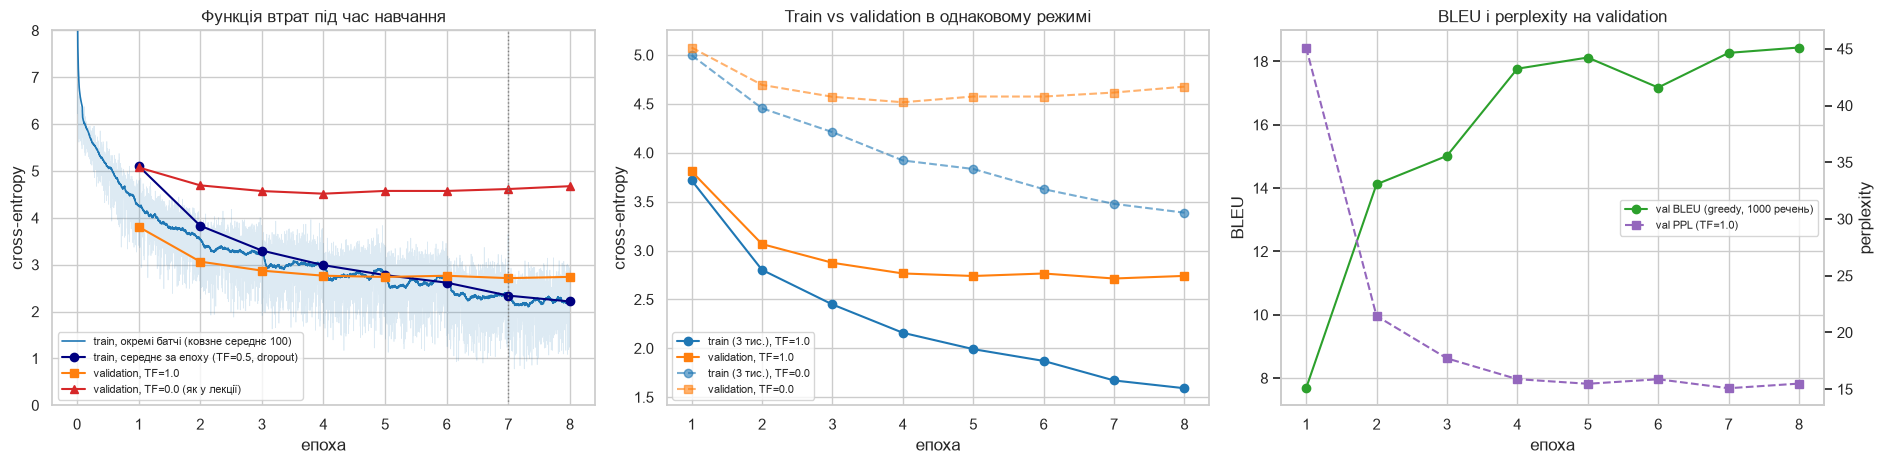

Розрив val − train (TF=1.0) за епохами: +0.091, +0.264, +0.426, +0.607, +0.748, +0.894, +1.043, +1.149


In [23]:
h = pd.DataFrame(history)
n_batches = len(train_loader)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

ax = axes[0]
x_b = np.arange(1, len(batch_history) + 1) / n_batches
ax.plot(x_b, batch_history, color='tab:blue', alpha=0.15, lw=0.5)
ax.plot(x_b, pd.Series(batch_history).rolling(100, min_periods=1).mean(), color='tab:blue', lw=1.2,
        label='train, окремі батчі (ковзне середнє 100)')
ax.plot(h['epoch'], h['train_loss'], 'o-', color='navy', label='train, середнє за епоху (TF=0.5, dropout)')
ax.plot(h['epoch'], h['val_tf1'], 's-', color='tab:orange', label='validation, TF=1.0')
ax.plot(h['epoch'], h['val_free'], '^-', color='tab:red', label='validation, TF=0.0 (як у лекції)')
ax.axvline(best_epoch, color='gray', ls=':', lw=1)
ax.set(title='Функція втрат під час навчання', xlabel='епоха', ylabel='cross-entropy')
ax.set_ylim(0, max(8, h['val_free'].max() + 0.3))
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(h['epoch'], h['train_eval_tf1'], 'o-', color='tab:blue', label='train (3 тис.), TF=1.0')
ax.plot(h['epoch'], h['val_tf1'], 's-', color='tab:orange', label='validation, TF=1.0')
ax.plot(h['epoch'], h['train_eval_free'], 'o--', color='tab:blue', alpha=0.6, label='train (3 тис.), TF=0.0')
ax.plot(h['epoch'], h['val_free'], 's--', color='tab:orange', alpha=0.6, label='validation, TF=0.0')
ax.set(title='Train vs validation в однаковому режимі', xlabel='епоха', ylabel='cross-entropy')
ax.legend(fontsize=8)

ax = axes[2]
ax.plot(h['epoch'], h['val_bleu'], 'o-', color='tab:green', label='val BLEU (greedy, 1000 речень)')
ax.set(title='BLEU і perplexity на validation', xlabel='епоха', ylabel='BLEU')
ax2 = ax.twinx()
ax2.plot(h['epoch'], np.exp(h['val_tf1']), 's--', color='tab:purple', label='val PPL (TF=1.0)')
ax2.set_ylabel('perplexity')
ax2.grid(False)
lines = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(lines, [l.get_label() for l in lines], fontsize=8, loc='center right')
plt.tight_layout()
plt.show()

gap = h['val_tf1'] - h['train_eval_tf1']
print('Розрив val − train (TF=1.0) за епохами:', ', '.join(f'{g:+.3f}' for g in gap))

### Аналіз кривих навчання

- На старті loss ≈ 9.39 = ln(11 956), тобто модель вгадує слово рівномірно з усього англійського словника (графік обрізаний на 8). Уже за першу третину епохи loss батчів падає до ≈ 5: модель швидко вивчає частотні слова (*the, of, to*) і пунктуацію.
- Середній train loss (TF = 0.5, dropout) знижується з 5.11 після 1-ї епохи до 2.22 після 8-ї. Val loss у режимі TF = 1.0 різко падає в перші три епохи (3.81 → 3.07 → 2.87), а з 4-ї епохи виходить на плато 2.71-2.77. Найкраща епоха 7-ма: val loss 2.714, perplexity 15.1. Після 6-ї епохи val loss не покращився, `ReduceLROnPlateau` зменшив lr до 5e-4, і на 7-й епосі val loss ще трохи знизився.
- Val BLEU (greedy, 1 000 речень) росте майже монотонно: 7.7 → 14.1 → 15.0 → 17.8 → 18.1 → 17.2 → 18.3 → 18.4.

На лівому графіку train loss (TF = 0.5) перші п'ять епох лежить вище за val loss (TF = 1.0). Це не означає, що на нових даних модель працює краще. Під час навчання на половині кроків декодер отримує власні (часто помилкові) передбачення, до того ж увімкнений dropout. Якщо оцінити підвибірку train у тому самому режимі, що й validation (середній графік), train завжди нижчий: після 1-ї епохи 3.72 проти 3.81 (TF = 1.0).

Перенавчання видно, якщо порівнювати в однаковому режимі (TF = 1.0): розрив val − train росте з +0.09 після 1-ї епохи до +1.15 після 8-ї. Train loss далі падає (до 1.59), а val з 4-ї епохи стоїть на місці. «Лекційний» val loss у режимі TF = 0.0 мінімальний на 4-й епосі (4.52), а потім росте до 4.68. Тобто з 4-5-ї епохи модель починає запам'ятовувати train. BLEU поки не падає, тому 8 епох я вважаю розумною межею. Для довшого навчання потрібна сильніша регуляризація або більше даних. Найкращі ваги я зберігав за val loss, тому для тесту взято 7-му епоху.

У режимі вільної генерації (TF = 0.0) val loss набагато вищий (≈ 4.5-4.7), ніж з teacher forcing (TF = 1.0, ≈ 2.7). Достатньо однієї помилки на початку речення, і всі наступні слова порівнюються з еталоном «не на своїх місцях». До того ж декодер робить рівно стільки кроків, скільки слів в еталоні. Тому якість перекладу я оцінюю за BLEU, а епоху вибираю за loss у режимі TF = 1.0.

В інструкції для простої моделі очікується loss ≈ 2-4, для добре налаштованої ≈ 1.5-3 на train. У мене train 2.22 (режим навчання) / 1.59 (TF = 1.0), val 2.71, тобто результат у межах очікуваного. У практиці теми 12 на Multi30k найкращий val loss був 3.286 (PPL ≈ 26.7). Тут PPL 15.1, хоча Europarl складніший і офіційніший. Головна причина в обсязі даних: їх у 5 разів більше (150 тис. пар проти 29 тис.). Набори різні, тож це лише грубе порівняння. Одна епоха тривала 8.2-10.2 хв, усе навчання 73 хв на GPU ноутбука (MPS).

## 10. Оцінка на тестовій вибірці

Завантажую найкращі ваги й рахую метрики на 3 000 тестових пар, які не використовувались ні для навчання, ні для вибору епохи:

- test loss / perplexity у двох режимах (як для validation);
- BLEU і chrF (бібліотека `sacrebleu`) для жадібного декодування до `<eos>`. BLEU рахую на токенізованому spaCy тексті в нижньому регістрі (обидві сторони токенізовані однаково, `tokenize='none'`). Тому це число не можна напряму порівнювати з офіційними результатами SacreBLEU на детокенізованому тексті, але для порівняння моделей і налаштувань у цьому ноутбуці воно коректне.

In [24]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=True))

test_tf1 = evaluate_fn(model, test_loader, DEVICE, 1.0)
test_free = evaluate_fn(model, test_loader, DEVICE, 0.0)

t0 = time.time()
test_hyps, test_attn = translate_many(model, test_df['de_tok'].tolist(), return_attention=True)
test_bleu, test_chrf = bleu_chrf(test_hyps, test_df['en_tok'])
decode_sec = time.time() - t0

test_df['hyp'] = [' '.join(strip_eos(hyp)) for hyp in test_hyps]
test_df['sent_bleu'] = [sacrebleu.sentence_bleu(hyp, [' '.join(ref)], tokenize='none').score
                        for hyp, ref in zip(test_df['hyp'], test_df['en_tok'])]
test_df['hyp_len'] = [len(strip_eos(hyp)) for hyp in test_hyps]
no_eos = np.mean([EOS not in hyp for hyp in test_hyps])
unk_share = np.mean([t == UNK for hyp in test_hyps for t in hyp])


def has_repeat(tokens):
    """True if the same word appears twice in a row ('natural natural')."""
    words = [t for t in strip_eos(tokens) if t.isalpha()]
    return any(a == b for a, b in zip(words, words[1:]))


rep_hyp = np.mean([has_repeat(h) for h in test_hyps])
rep_ref = np.mean([has_repeat(r) for r in test_df['en_tok']])

results = pd.DataFrame({
    'метрика': ['test loss, TF=1.0', 'test perplexity (TF=1.0)', 'test loss, TF=0.0 (як у лекції)', 'test BLEU (greedy)',
                'test chrF (greedy)', 'довжина перекладу / еталону', 'частка <unk> у перекладах, %',
                'переклади без <eos> (обрізані), %', 'переклади з повтором слова поспіль, %',
                'еталони з повтором слова поспіль, %'],
    'значення': [test_tf1, math.exp(test_tf1), test_free, test_bleu, test_chrf,
                 test_df['hyp_len'].sum() / test_df['en_len'].sum(), 100 * unk_share, 100 * no_eos,
                 100 * rep_hyp, 100 * rep_ref]})
display(results.style.format({'значення': '{:.3f}'}, escape='html').hide(axis='index'))
print(f'Переклад {len(test_df):,} речень зайняв {decode_sec:.1f} с')

метрика,значення
"test loss, TF=1.0",2.705
test perplexity (TF=1.0),14.962
"test loss, TF=0.0 (як у лекції)",4.630
test BLEU (greedy),19.359
test chrF (greedy),42.124
довжина перекладу / еталону,0.930
"частка <unk> у перекладах, %",2.028
"переклади без <eos> (обрізані), %",0.000
"переклади з повтором слова поспіль, %",55.900
"еталони з повтором слова поспіль, %",0.167


Переклад 3,000 речень зайняв 2.6 с


### Якість залежно від довжини речення

,речень,BLEU,chrF
"довжина de, токенів",,,
1–10,511,21.91,43.46
11–15,770,19.10,41.35
16–20,826,18.86,41.87
21–25,669,19.86,42.67
26–30,224,17.95,41.85


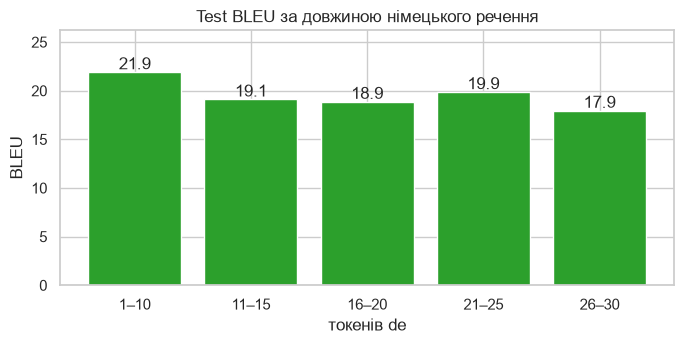

In [25]:
bins = [0, 10, 15, 20, 25, MAX_TOKENS]
test_df['len_bin'] = pd.cut(test_df['de_len'], bins=bins, labels=[f'{a + 1}–{b}' for a, b in zip(bins[:-1], bins[1:])])
by_len = []
for name, g in test_df.groupby('len_bin', observed=True):
    b, c = bleu_chrf([h.split() for h in g['hyp']], g['en_tok'])
    by_len.append({'довжина de, токенів': name, 'речень': len(g), 'BLEU': b, 'chrF': c})
by_len = pd.DataFrame(by_len)
display(by_len.round(2).set_index('довжина de, токенів'))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(by_len['довжина de, токенів'].astype(str), by_len['BLEU'], color='tab:green')
ax.set(title='Test BLEU за довжиною німецького речення', xlabel='токенів de', ylabel='BLEU',
       ylim=(0, by_len['BLEU'].max() * 1.15 + 1))
for i, v in enumerate(by_len['BLEU']):
    ax.text(i, v + 0.3, f'{v:.1f}', ha='center')
plt.tight_layout()
plt.show()

### Жадібне декодування vs beam search

Жадібний пошук на кожному кроці бере найімовірніше слово, але це не гарантує найімовірнішого речення. Beam search тримає `k = 5` найкращих часткових гіпотез. Бали нормуються на довжину (length penalty GNMT, α = 0.7), щоб пошук не надавав перевагу занадто коротким перекладам. Порівнюю на перших 500 тестових реченнях.

In [26]:
@torch.no_grad()
def beam_search(model, src_tokens, beam_size=BEAM_SIZE, max_len=MAX_OUTPUT_LEN, alpha=0.7):
    """Beam search for one sentence; returns the best token list (without <sos>, with <eos> if generated)."""
    model.eval()
    src = numericalize(src_tokens, de_vocab).unsqueeze(1).to(DEVICE)       # (src_len, 1)
    encoder_outputs, hidden = model.encoder(src)                           # (src_len, 1, 2H), (1, H)
    mask = model.create_mask(src)                                          # (1, src_len)
    hyps = torch.full((1, 1), SOS_IDX, dtype=torch.long, device=DEVICE)    # alive hypotheses (n, t)
    scores = torch.zeros(1, device=DEVICE)                                 # their summed log-probs
    finished = []

    def length_penalty(length):
        return ((5 + length) / 6) ** alpha

    for _ in range(max_len):
        n = hyps.shape[0]
        output, new_hidden, _ = model.decoder(hyps[:, -1], hidden, encoder_outputs.expand(-1, n, -1),
                                              mask.expand(n, -1))
        cand = (scores.unsqueeze(1) + output.log_softmax(-1)).view(-1)       # (n * V,)
        top_scores, top_idx = cand.topk(beam_size)
        beam_idx, tok_idx = top_idx // OUTPUT_DIM, top_idx % OUTPUT_DIM
        hyps = torch.cat([hyps[beam_idx], tok_idx.unsqueeze(1)], dim=1)
        hidden, scores = new_hidden[beam_idx], top_scores
        is_eos = tok_idx == EOS_IDX
        for i in torch.nonzero(is_eos).flatten().tolist():
            finished.append((hyps[i, 1:].tolist(), scores[i].item() / length_penalty(hyps.shape[1] - 1)))
        hyps, scores, hidden = hyps[~is_eos], scores[~is_eos], hidden[~is_eos]
        if len(finished) >= beam_size or hyps.shape[0] == 0:
            break
    if not finished:                                                       # no hypothesis reached <eos>
        finished = [(hyps[0, 1:].tolist(), scores[0].item() / length_penalty(hyps.shape[1] - 1))]
    best = max(finished, key=lambda x: x[1])[0]
    return en_vocab.lookup_tokens(best)


beam_df = test_df.iloc[:N_BEAM]
t0 = time.time()
beam_hyps = [beam_search(model, toks) for toks in beam_df['de_tok']]
beam_sec = time.time() - t0
greedy_sub = [h.split() for h in beam_df['hyp']]
g_bleu, g_chrf = bleu_chrf(greedy_sub, beam_df['en_tok'])
b_bleu, b_chrf = bleu_chrf(beam_hyps, beam_df['en_tok'])
test_df.loc[:N_BEAM - 1, 'beam'] = [' '.join(strip_eos(h)) for h in beam_hyps]
display(pd.DataFrame({'декодування': ['greedy', f'beam search (k={BEAM_SIZE})'], 'BLEU': [g_bleu, b_bleu],
                      'chrF': [g_chrf, b_chrf],
                      'довжина / еталон': [sum(map(len, greedy_sub)) / beam_df['en_len'].sum(),
                                           sum(len(strip_eos(h)) for h in beam_hyps) / beam_df['en_len'].sum()]})
        .round(3).set_index('декодування'))
print(f'Beam search для {N_BEAM} речень: {beam_sec:.0f} с (≈ {1000 * beam_sec / N_BEAM:.0f} мс на речення)')

,BLEU,chrF,довжина / еталон
декодування,,,
greedy,19.847,42.906,0.926
beam search (k=5),22.590,45.684,0.921


Beam search для 500 речень: 44 с (≈ 88 мс на речення)


### Коментар до результатів на тесті

- Test loss 2.705 (PPL 15.0) майже збігається з найкращим val loss 2.714. Тобто вибір епохи за validation не «підігнав» модель під validation, і тестові речення для моделі не складніші.
- Greedy-декодування дає BLEU 19.4 і chrF 42.1. Переклади в середньому на 7 % коротші за еталони (0.930), тому BLEU множиться на штраф за стислість exp(1 − 1/0.930) ≈ 0.93. Виходить, що близько 7 % BLEU втрачено саме на «недоперекладі». `<unk>` становить 2.0 % згенерованих токенів; жоден переклад не обірвався на ліміті довжини.
- Найпомітніший дефект: повтори. У 55.9 % перекладів одне й те саме слово трапляється двічі поспіль (без урахування розділових знаків і `<unk>`: *natural natural*, *european european*, *the the*), а в еталонах лише у 0.17 %. Це типова проблема жадібного RNN-декодера без механізму покриття (coverage): модель не пам'ятає, які слова джерела вже переклала.
- Довжина речення впливає помірно: BLEU 21.9 для речень до 10 токенів і 18.0 для 26-30 токенів, між ними 18.9-19.9. Це узгоджується з тим, що увага знімає «вузьке місце» одного контекстного вектора (Bahdanau et al., 2015). Модель без уваги я не навчав, тому тут це лише спостереження, а не доведений ефект.
- Beam search (k = 5) на перших 500 тестових реченнях дає +2.7 BLEU (19.8 → 22.6) і +2.8 chrF. Це найдешевше покращення, бо модель не треба перенавчати. Ціна в швидкості: 88 мс на речення проти ≈ 1 мс на речення в батчевому greedy. Beam виправляє частину помилок (у прикладах нижче *the is the is is closed* стає *the list of presidents is closed*), але повтори на кшталт *european european* лишаються.

## 11. Приклади перекладів

### 11.1. Речення з тестової вибірки

10 випадкових речень серед перших 500 тестових (для них є і beam-переклад), довжиною ≤ 18 токенів, щоб таблиця була читабельною. Стовпець `BLEU` містить sentence-BLEU жадібного перекладу.

In [27]:
pool_ex = test_df.iloc[:N_BEAM]
pool_ex = pool_ex[pool_ex['de_len'] <= 18]
examples = pool_ex.sample(min(10, len(pool_ex)), random_state=3)
with pd.option_context('display.max_colwidth', 200):
    display(examples[['de', 'en', 'hyp', 'beam', 'sent_bleu']]
            .rename(columns={'de': 'німецьке речення', 'en': 'еталон', 'hyp': 'модель (greedy)',
                             'beam': f'модель (beam {BEAM_SIZE})', 'sent_bleu': 'BLEU'})
            .style.format({'BLEU': '{:.1f}'}, na_rep='—', escape='html').hide(axis='index'))

німецьке речення,еталон,модель (greedy),модель (beam 5),BLEU
"Meine Fraktion kann nicht a priori hinnehmen, dass wir jetzt eine Prüfung der Vorausschau diskutieren.","My group cannot accept, a priori, that we are now discussing a revision of the financial perspective.",my group can not accept a <unk> that we now discuss the the of the .,my group can not accept a <unk> that we shall now discuss the review of the .,23.1
"Nord und Süd, die einzelnen Weinbauregionen - eine Vielfalt von Meinungen und Interessen trafen aufeinander.","North and south, the individual wine-growing regions - a wide variety of opinions and interests have been represented.","north and and south - the , the various of - ethnic diversity and a variety of opinions .","north and south sport , the various <unk> - have a variety of opinions and interests .",11.7
"Überschwemmungen sind natürliche Phänomene, denen zuvorgekommen werden muss und deren Auswirkungen verhindert werden müssen.",Floods are natural phenomena that need to be anticipated and the effects prevented.,floods are natural natural that must be tackled and must be to to their effects .,floods are natural natural that need to be tackled and must must be overcome their effects .,12.0
"Ich meine, daß ein Kompromiß gut über die Kennzeichnung auf dem Etikett gefunden werden kann.",I think that it is possible to find a compromise by means of information on the label.,i think that a compromise can be found on labelling labelling on the label .,i think that a compromise can be found on labelling label on the label .,21.7
Unsere hauptsächlichen Vorschläge lauten:,Our main proposals are:,our <unk> proposals :,our main proposals are : :,16.4
"Ich kann daher verstehen, warum Sie die Anwesenden zählen wollen.",I can understand why you would have to take a head count.,i can therefore understand why you are keen to present .,i can therefore understand why you want to present .,15.9
"Können Sie bestätigen, daß die Rednerliste geschlossen ist?",Can you confirm that the list of speakers is closed?,can you confirm that the is the is is closed ?,can you confirm that the list of presidents is closed ?,46.9
Das ist das Problem des politischen Europas!,This is the problem of political Europe!,that is the issue of political political !,that is the problem of political europe !,16.5
Wir wollen auch mehr Transparenz bei der europäischen Förderung.,We also want more transparency in the way Europe provides support.,we also want greater transparency in european european .,we also want greater transparency in european european .,16.7
"Zudem ist vorgeschlagen, EU-Fördergelder einzusetzen, um die ländliche Lebensqualität zu steigern.",There is also a proposal to use EU funding to improve the quality of life in rural communities.,it is also proposed to resort to quality quality of the increase the quality of life .,it is also proposed to resort to the quality of quality .,16.8


### 11.2. Власні речення

Кілька простих речень, які я склав сам, з моїм перекладом як еталоном. Я підібрав їх так, щоб перевірити типові для німецької зміни порядку слів: дієприкметник у кінці, модальне дієслово + інфінітив, підрядне речення з дієсловом у кінці, відокремлюваний префікс. Одне речення взято поза тематикою Європарламенту.

In [28]:
own_sentences = [
    ('Ich habe den Bericht gestern gelesen.', 'I read the report yesterday.'),
    ('Wir müssen diese Frage morgen im Parlament diskutieren.', 'We must discuss this question in Parliament tomorrow.'),
    ('Ich glaube, dass die Kommission einen neuen Vorschlag vorlegen wird.',
     'I believe that the Commission will present a new proposal.'),
    ('Ich stimme diesem Bericht voll und ganz zu.', 'I fully agree with this report.'),
    ('Die Bürger erwarten von uns konkrete Ergebnisse.', 'Citizens expect concrete results from us.'),
    ('Mein Hund spielt gern im Garten.', 'My dog likes to play in the garden.'),
]
own_rows, own_outputs = [], {}
for de_sent, my_ref in own_sentences:
    en_tokens, de_tokens, att = translate_sentence(de_sent, model)
    own_outputs[de_sent] = (en_tokens, de_tokens, att)
    beam = beam_search(model, de_tokens[1:-1])
    oov = [t for t in de_tokens[1:-1] if t not in de_vocab.stoi]
    own_rows.append({'німецьке речення': de_sent, 'мій переклад': my_ref,
                     'модель (greedy)': ' '.join(strip_eos(en_tokens)), f'модель (beam {BEAM_SIZE})': ' '.join(strip_eos(beam)),
                     'OOV (de)': ', '.join(oov) or '—'})
with pd.option_context('display.max_colwidth', 200):
    display(pd.DataFrame(own_rows).style.format(escape='html').hide(axis='index'))

німецьке речення,мій переклад,модель (greedy),модель (beam 5),OOV (de)
Ich habe den Bericht gestern gelesen.,I read the report yesterday.,i have read the report yesterday .,i have read the report yesterday .,—
Wir müssen diese Frage morgen im Parlament diskutieren.,We must discuss this question in Parliament tomorrow.,we need to discuss this question in parliament .,we need to discuss this question in parliament .,—
"Ich glaube, dass die Kommission einen neuen Vorschlag vorlegen wird.",I believe that the Commission will present a new proposal.,i believe that the commission will put forward a new proposal .,i believe that the commission will put forward a new proposal .,—
Ich stimme diesem Bericht voll und ganz zu.,I fully agree with this report.,i fully subscribe to this report .,i fully subscribe to this report .,—
Die Bürger erwarten von uns konkrete Ergebnisse.,Citizens expect concrete results from us.,the expect expect expecting concrete results .,the citizens expect expecting concrete results .,—
Mein Hund spielt gern im Garten.,My dog likes to play in the garden.,my <unk> is to to <unk> .,i would like to <unk> <unk> .,garten


### Коментар до прикладів

Типові для Європарламенту тестові речення модель інколи перекладає майже дослівно правильно (`test[339]` у розділі 12, sentence-BLEU 83.9; з beam search: *that is the problem of political europe !*). У довших реченнях загальний зміст зазвичай зберігається, але трапляються типові помилки:

- повтори (*natural natural*, *european european*, *labelling labelling*);
- `<unk>` на місці рідкісних слів (*a priori* → *a `<unk>`*);
- пропуски (від *eine Prüfung der Vorausschau* лишилося *the the of the*);
- заміни близьких за контекстом слів (*list of presidents* замість *list of speakers*).

Власні речення:

1. *Ich habe den Bericht gestern gelesen.* → *i have read the report yesterday .* Переклад правильний: дієприкметник *gelesen* з кінця речення перенесено на 3-тю позицію, а *gestern* у кінець.
2. *Wir müssen diese Frage morgen im Parlament diskutieren.* → *we need to discuss this question in parliament .* Інфінітив *diskutieren* правильно перенесено вперед, але слово *morgen* загубилось, хоча воно є у словнику. Це приклад пропуску.
3. *…, dass die Kommission einen neuen Vorschlag vorlegen wird.* → *… that the commission will put forward a new proposal .* Правильно, ще й з типовим для Європарламенту зворотом *put forward*.
4. *Ich stimme diesem Bericht voll und ganz zu.* → *i fully subscribe to this report .* Відокремлюваний префікс *stimme … zu* модель зрозуміла правильно (*subscribe to* = «підтримую»).
5. *Die Bürger erwarten von uns konkrete Ergebnisse.* → greedy: *the expect expect expecting concrete results .* Переклад зламаний: є повтор, загублено *citizens* і *from us*. Beam трохи кращий (*the citizens expect expecting concrete results .*), але повтор лишився.
6. *Mein Hund spielt gern im Garten.* (поза тематикою) → *my `<unk>` is to to `<unk>` .* Повна невдача: *garten* не входить до словника (OOV), *Hund* у парламентських текстах трапляється рідко, а побутової лексики в корпусі майже немає.

Модель добре засвоїла стиль і типові звороти Європарламенту та базові перестановки німецького порядку слів. Слабкі місця: рідкісні слова, повтори і пропуски.

## 12. Візуалізація механізму уваги

Для кожного згенерованого слова (рядок) показано ваги уваги `α_{t,s}` по токенах німецького речення (стовпці); сума кожного рядка дорівнює 1. Чим світліша клітинка, тим більше декодер «дивився» на це слово джерела, коли генерував слово рядка. Значення ≥ 0.25 підписані.

У Bahdanau-увазі ваги для слова `y_t` рахуються зі стану декодера, який був ще до генерації цього слова (`s_{t−1}`). Тобто увага показує, яку частину джерела модель вирішила перекласти наступною.

In [29]:
def plot_attention(src_tokens, trg_tokens, attention, title='', ax=None, annotate=0.25):
    """Heatmap of attention (rows = generated tokens, columns = source tokens), like plot_attention in the lecture."""
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(0.55 * len(src_tokens) + 2.5, 0.45 * len(trg_tokens) + 1.8))
    im = ax.imshow(attention, cmap='bone', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(src_tokens)), labels=src_tokens, rotation=60, ha='right', fontsize=11)
    ax.set_yticks(range(len(trg_tokens)), labels=trg_tokens, fontsize=11)
    ax.grid(False)
    for i in range(attention.shape[0]):
        for j in range(attention.shape[1]):
            if attention[i, j] >= annotate:
                ax.text(j, i, f'{attention[i, j]:.2f}', ha='center', va='center', fontsize=8,
                        color='black' if attention[i, j] > 0.6 else 'white')
    ax.set_xlabel('джерело (de)')
    ax.set_ylabel('переклад моделі (en)')
    ax.set_title(title, fontsize=11)
    if show:
        plt.colorbar(im, ax=ax, fraction=0.03)
        plt.tight_layout()
        plt.show()


def top_alignments(src_tokens, trg_tokens, attention):
    """For every generated token: the source token with the largest attention weight."""
    return ', '.join(f'{t}→{src_tokens[j]} ({attention[i, j]:.2f})'
                     for i, (t, j) in enumerate(zip(trg_tokens, attention.argmax(1))))

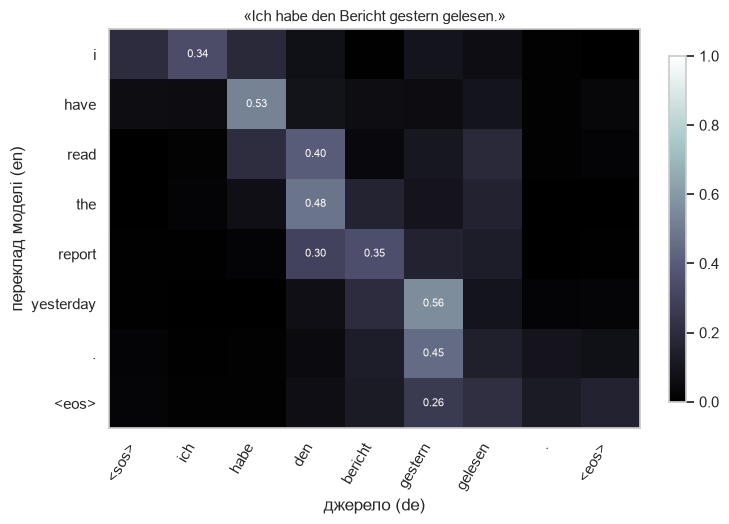

Найбільша вага: i→ich (0.34), have→habe (0.53), read→den (0.40), the→den (0.48), report→bericht (0.35), yesterday→gestern (0.56), .→gestern (0.45), <eos>→gestern (0.26) 



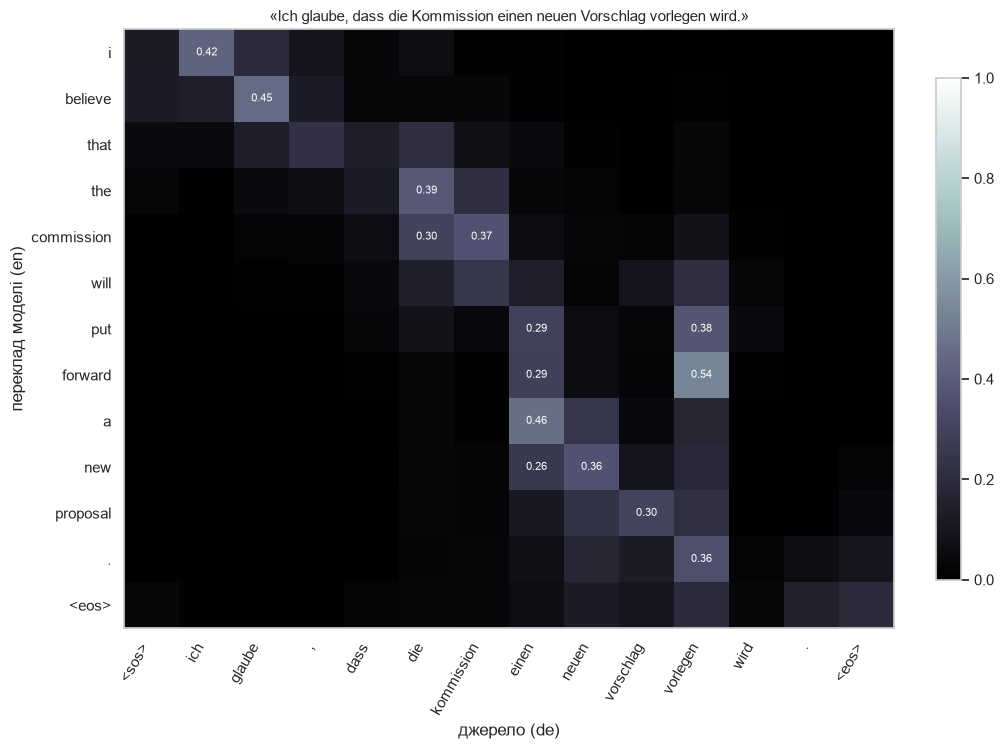

Найбільша вага: i→ich (0.42), believe→glaube (0.45), that→, (0.22), the→die (0.39), commission→kommission (0.37), will→kommission (0.25), put→vorlegen (0.38), forward→vorlegen (0.54), a→einen (0.46), new→neuen (0.36), proposal→vorschlag (0.30), .→vorlegen (0.36), <eos>→vorlegen (0.20) 



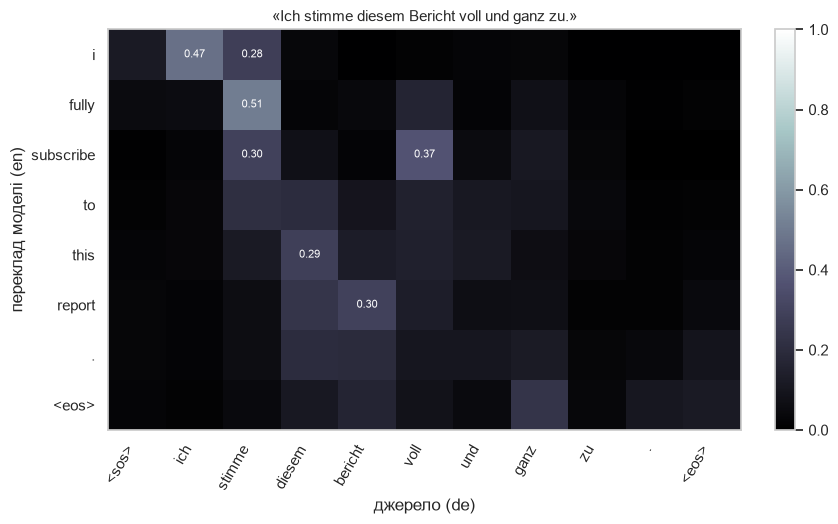

Найбільша вага: i→ich (0.47), fully→stimme (0.51), subscribe→voll (0.37), to→stimme (0.21), this→diesem (0.29), report→bericht (0.30), .→diesem (0.20), <eos>→ganz (0.24) 



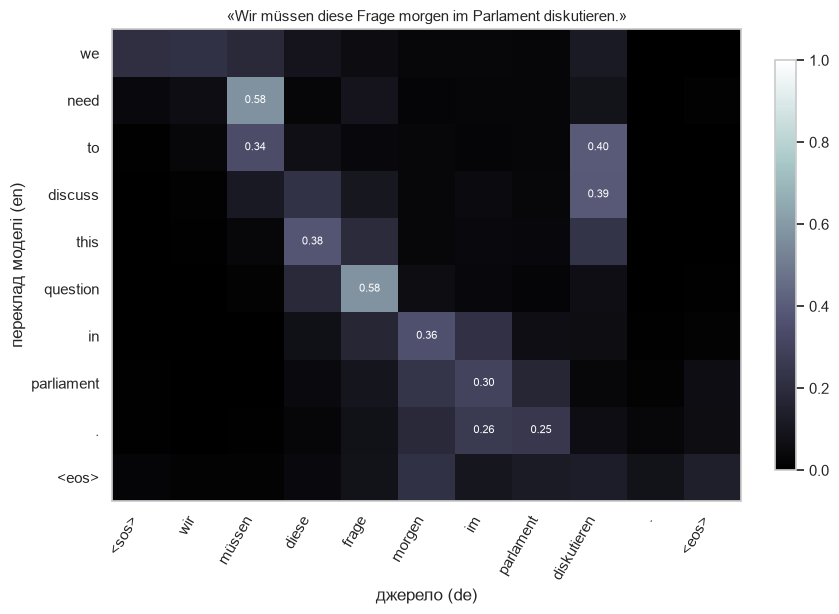

Найбільша вага: we→wir (0.22), need→müssen (0.58), to→diskutieren (0.40), discuss→diskutieren (0.39), this→diese (0.38), question→frage (0.58), in→morgen (0.36), parliament→im (0.30), .→im (0.26), <eos>→morgen (0.23) 



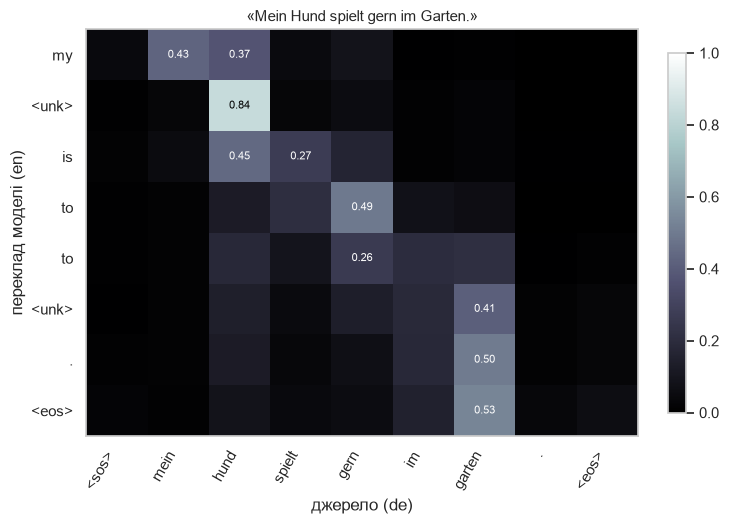

Найбільша вага: my→mein (0.43), <unk>→hund (0.84), is→hund (0.45), to→gern (0.49), to→gern (0.26), <unk>→garten (0.41), .→garten (0.50), <eos>→garten (0.53) 



In [30]:
attention_examples = [
    'Ich habe den Bericht gestern gelesen.',
    'Ich glaube, dass die Kommission einen neuen Vorschlag vorlegen wird.',
    'Ich stimme diesem Bericht voll und ganz zu.',
    'Wir müssen diese Frage morgen im Parlament diskutieren.',
    'Mein Hund spielt gern im Garten.',
]
for sent in attention_examples:
    en_tokens, de_tokens, att = own_outputs[sent]
    plot_attention(de_tokens, en_tokens, att, title=f'«{sent}»')
    print('Найбільша вага:', top_alignments(de_tokens, en_tokens, att), '\n')

Два приклади з тестової вибірки: вдалий переклад довшого речення та невдалий (низький sentence-BLEU).

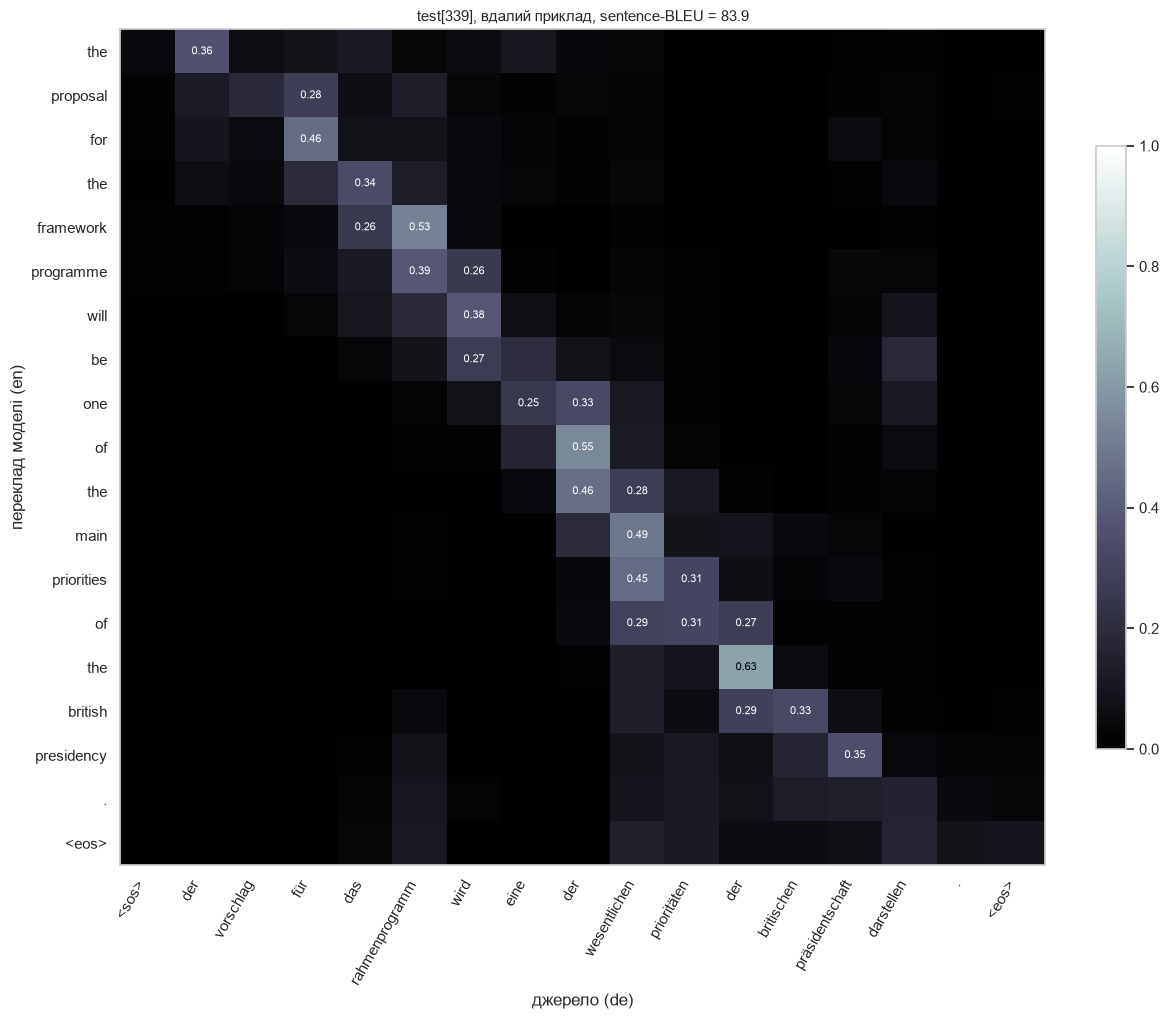

DE : Der Vorschlag für das Rahmenprogramm wird eine der wesentlichen Prioritäten der britischen Präsidentschaft darstellen.
REF: The proposal for the framework programme will be one of the basic priorities of the British Presidency.
HYP: the proposal for the framework programme will be one of the main priorities of the british presidency .
Найбільша вага: the→der (0.36), proposal→für (0.28), for→für (0.46), the→das (0.34), framework→rahmenprogramm (0.53), programme→rahmenprogramm (0.39), will→wird (0.38), be→wird (0.27), one→der (0.33), of→der (0.55), the→der (0.46), main→wesentlichen (0.49), priorities→wesentlichen (0.45), of→prioritäten (0.31), the→der (0.63), british→britischen (0.33), presidency→präsidentschaft (0.35), .→darstellen (0.16), <eos>→darstellen (0.16) 



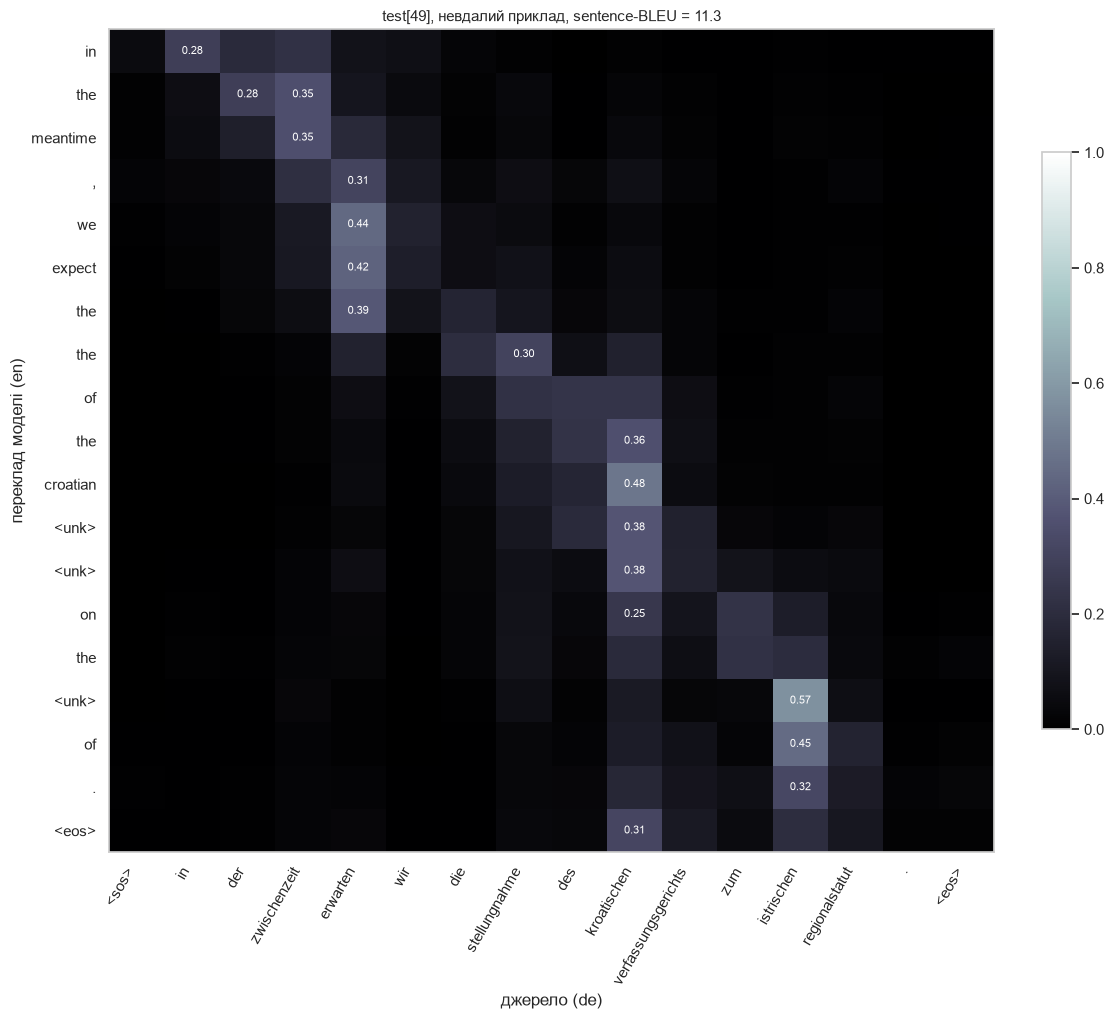

DE : In der Zwischenzeit erwarten wir die Stellungnahme des kroatischen Verfassungsgerichts zum istrischen Regionalstatut.
REF: Meanwhile we are looking forward to the opinion of the Croatian Constitutional Court on the Istrian statute.
HYP: in the meantime , we expect the the of the croatian <unk> <unk> on the <unk> of .
Найбільша вага: in→in (0.28), the→zwischenzeit (0.35), meantime→zwischenzeit (0.35), ,→erwarten (0.31), we→erwarten (0.44), expect→erwarten (0.42), the→erwarten (0.39), the→stellungnahme (0.30), of→des (0.24), the→kroatischen (0.36), croatian→kroatischen (0.48), <unk>→kroatischen (0.38), <unk>→kroatischen (0.38), on→kroatischen (0.25), the→zum (0.22), <unk>→istrischen (0.57), of→istrischen (0.45), .→istrischen (0.32), <eos>→kroatischen (0.31) 



In [31]:
cand = test_df[test_df['de_len'].between(14, 22)]
good_idx = cand['sent_bleu'].idxmax()
bad_pool = cand[cand['sent_bleu'] < 15]
bad_idx = (bad_pool if len(bad_pool) else cand).sample(1, random_state=1).index[0]
for label, idx in [('вдалий', good_idx), ('невдалий', bad_idx)]:
    row = test_df.loc[idx]
    de_tokens = [SOS] + row['de_tok'] + [EOS]
    plot_attention(de_tokens, test_hyps[idx], test_attn[idx],
                   title=f'test[{idx}], {label} приклад, sentence-BLEU = {row["sent_bleu"]:.1f}')
    print('DE :', row['de'])
    print('REF:', row['en'])
    print('HYP:', row['hyp'])
    print('Найбільша вага:', top_alignments(de_tokens, test_hyps[idx], test_attn[idx]), '\n')

### 12.1. Кількісний аналіз уваги на всій тестовій вибірці

Щоб висновки не спиралися лише на кілька картинок, для кожного з 3 000 тестових перекладів рахую:

- гостроту, тобто середню максимальну вагу в рядку (1.0 = вся увага на одному слові);
- нормовану ентропію рядка `H(α_t) / log(S)` (0 означає один токен, 1 означає рівномірний розподіл по реченню);
- монотонність, тобто кореляцію Спірмена між позицією згенерованого слова і позицією найбільшої ваги в джерелі (1.0 = ідеальна діагональ);
- частку уваги на службових токенах `<sos>` і `<eos>` джерела.

In [32]:
def attention_stats(att):
    """att: (T_out, S) incl. the <eos> step (last row) and <sos>/<eos> source columns."""
    S = att.shape[1]
    ent = -(att * np.log(att + 1e-12)).sum(1) / np.log(S)
    rows = att[:-1] if att.shape[0] > 1 else att       # word rows (without the final <eos> step)
    argmax = rows.argmax(1)
    rho = spearmanr(np.arange(len(argmax)), argmax).correlation if len(argmax) >= 4 and argmax.std() > 0 else np.nan
    return {'sharpness': att.max(1).mean(), 'entropy': ent.mean(), 'monotonic_rho': rho,
            'sos_mass': att[:, 0].mean(), 'eos_mass': att[:, -1].mean(),
            'eos_row_on_eos': att[-1, -1]}


att_stats = pd.DataFrame([attention_stats(a) for a in test_attn])
att_stats['sent_bleu'] = test_df['sent_bleu'].values
att_stats['de_len'] = test_df['de_len'].values

summary = att_stats[['sharpness', 'entropy', 'monotonic_rho', 'sos_mass', 'eos_mass', 'eos_row_on_eos']].describe().T[
    ['mean', '25%', '50%', '75%']]
summary.index = ['гострота (макс. вага в рядку)', 'нормована ентропія рядка', 'монотонність (Спірмен)',
                 'вага на <sos> джерела', 'вага на <eos> джерела', 'вага на <eos> при генерації <eos>']
display(summary.round(3))
print(f'Речень з монотонністю ρ > 0.8: {(att_stats["monotonic_rho"] > 0.8).mean():.1%}; '
      f'ρ < 0.5: {(att_stats["monotonic_rho"] < 0.5).mean():.1%}')

att_stats['entropy_q'] = pd.qcut(att_stats['entropy'], 4, labels=['Q1 (найгостріша)', 'Q2', 'Q3', 'Q4 (найрозмитіша)'])
by_q = att_stats.groupby('entropy_q', observed=True).agg(речень=('sent_bleu', 'size'),
                                                         ентропія=('entropy', 'mean'),
                                                         sentence_BLEU=('sent_bleu', 'mean'),
                                                         довжина_de=('de_len', 'mean'))
display(by_q.round(3))
rho_e, p_e = spearmanr(att_stats['entropy'], att_stats['sent_bleu'])
print(f'Кореляція Спірмена «ентропія уваги ↔ sentence-BLEU»: {rho_e:.3f} (p = {p_e:.1e})')

,mean,25%,50%,75%
гострота (макс. вага в рядку),0.347,0.300,0.338,0.387
нормована ентропія рядка,0.688,0.639,0.682,0.731
монотонність (Спірмен),0.901,0.916,0.968,0.986
вага на <sos> джерела,0.014,0.006,0.011,0.018
вага на <eos> джерела,0.013,0.004,0.008,0.016
вага на <eos> при генерації <eos>,0.067,0.021,0.046,0.090


Речень з монотонністю ρ > 0.8: 87.2%; ρ < 0.5: 3.9%


,речень,ентропія,sentence_BLEU,довжина_de
entropy_q,,,,
Q1 (найгостріша),750,0.604,21.892,17.945
Q2,750,0.661,20.438,18.395
Q3,750,0.705,17.832,16.961
Q4 (найрозмитіша),750,0.780,16.364,13.785


Кореляція Спірмена «ентропія уваги ↔ sentence-BLEU»: -0.176 (p = 2.3e-22)


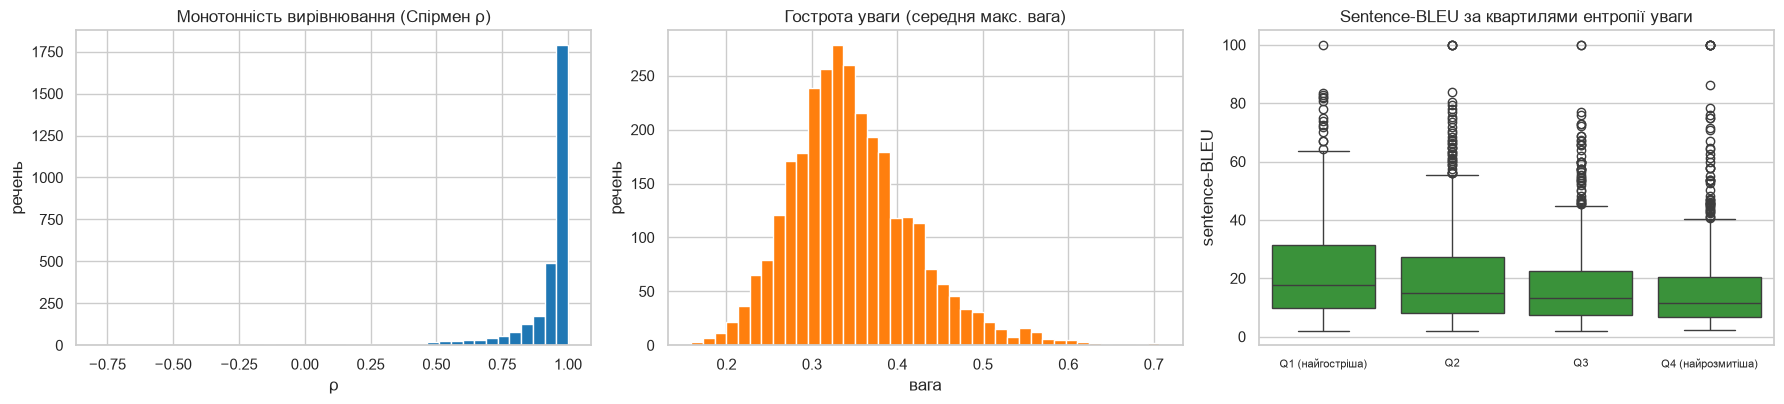

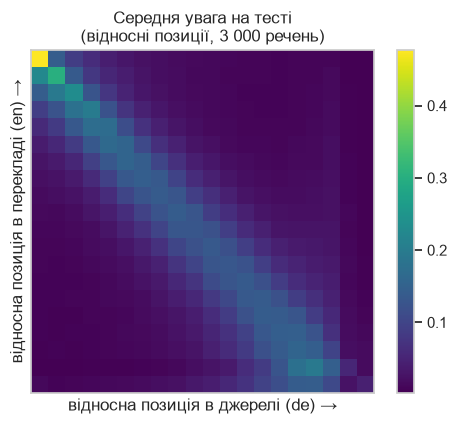

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
axes[0].hist(att_stats['monotonic_rho'].dropna(), bins=40, color='tab:blue')
axes[0].set(title='Монотонність вирівнювання (Спірмен ρ)', xlabel='ρ', ylabel='речень')
axes[1].hist(att_stats['sharpness'], bins=40, color='tab:orange')
axes[1].set(title='Гострота уваги (середня макс. вага)', xlabel='вага', ylabel='речень')
sns.boxplot(data=att_stats, x='entropy_q', y='sent_bleu', ax=axes[2], color='tab:green')
axes[2].set(title='Sentence-BLEU за квартилями ентропії уваги', xlabel='', ylabel='sentence-BLEU')
axes[2].tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

# average attention "diagonal": relative source position vs relative target position (all test sentences)
grid = np.zeros((20, 20))
for att in test_attn:
    rows = att[:-1]
    if len(rows) < 2:
        continue
    T, S = rows.shape
    for t in range(T):
        for s in range(1, S - 1):                         # skip <sos>/<eos> columns
            grid[int(19 * t / (T - 1)), int(19 * (s - 1) / max(S - 3, 1))] += rows[t, s]
grid = grid / grid.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(grid, cmap='viridis', origin='upper')
ax.set(title='Середня увага на тесті\n(відносні позиції, 3 000 речень)', xlabel='відносна позиція в джерелі (de) →',
       ylabel='відносна позиція в перекладі (en) →', xticks=[], yticks=[])
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

### 12.2. Як працює увага в моїй моделі: висновки

1. Вирівнювання здебільшого діагональне. На середній карті уваги по 3 000 тестових реченнях добре видно діагональну смугу. Кореляція Спірмена між позицією перекладеного слова і позицією максимуму уваги має медіану 0.97 (середнє 0.90); у 87.2 % речень ρ > 0.8 і лише в 3.9 % ρ < 0.5. У головних реченнях німецька й англійська мають схожий порядок слів, тому більшість слів перекладається «по черзі», і увага рухається зліва направо разом із декодером. Модель вивчила це сама, жодних даних про вирівнювання слів я їй не давав.
2. Коли цього вимагає німецький порядок слів, увага «перестрибує»:
   - *Wir müssen diese Frage … diskutieren* → *we need to discuss this question …*: для *to* і *discuss* увага переходить з *müssen* (2-га позиція) на *diskutieren* у самому кінці речення (0.40 і 0.39), а потім повертається до *diese* (0.38) і *Frage* (0.58). Модель переносить інфінітив з кінця речення вперед.
   - *…, dass die Kommission einen neuen Vorschlag vorlegen wird* → *… will put forward a new proposal*: *put* (0.38) і *forward* (0.54) дивляться на *vorlegen* наприкінці підрядного речення, після чого увага повертається до *einen* (0.46) для *a*. На карті це блок поза діагоналлю.
3. Одне слово джерела може дати кілька слів перекладу. Німецьке складне слово *Rahmenprogramm* дає *framework* (0.53) + *programme* (0.39), *vorlegen* дає *put* + *forward*, *Zwischenzeit* дає *the meantime*. На карті кілька рядків поспіль дивляться в той самий стовпчик.
4. Максимум уваги не завжди припадає на словниковий відповідник. У *Ich habe den Bericht gestern gelesen* слово *read* дивиться переважно на *den* (0.40), а не на *gelesen*. У *Ich stimme diesem Bericht voll und ganz zu* *fully* дивиться на *stimme* (0.51), *subscribe* на *voll* (0.37), а частку *zu* модель майже не «бачить», хоча *stimme … zu* перекладає правильно. Причин дві:
   - у Bahdanau-увазі ваги для слова `y_t` рахуються зі стану `s_{t−1}`, ще до вибору слова;
   - енкодер двонаправлений, тож стан на позиції *den* уже містить інформацію про весь «хвіст» речення, зокрема про *gelesen* (його прочитав зворотний GRU).

   Тому увага показує, *звідки* декодер бере інформацію, а не точний словниковий відповідник, і піки можуть зміщуватися на ±1 токен.
5. Увага м'яка і розподілена. Середня максимальна вага в рядку лише 0.35, нормована ентропія 0.69. Зазвичай вага ділиться між 2-4 сусідніми токенами, тому на картах видно смугу, а не окремі клітинки. Це узгоджується з п. 4: сусідні стани енкодера несуть схожу інформацію.
6. На службові токени `<sos>` і `<eos>` джерела припадає в середньому лише ≈ 1.4 % і 1.3 % уваги. Навіть на кроці генерації `<eos>` на `<eos>` джерела припадає лише 6.7 %. Модель вирішує зупинитися за станом декодера і при цьому дивиться на останні змістові слова (*gestern*, *vorlegen*, *Garten*), а не на маркер кінця.
7. За увагою інколи можна помітити помилку:
   - речення з найрозмитішою увагою (квартиль Q4 за ентропією) мають середній sentence-BLEU 16.4, а найгостріший квартиль Q1 має 21.9 (кореляція Спірмена −0.18, p ≈ 2·10⁻²²). При цьому речення Q4 найкоротші (13.8 токена проти 17.9), а короткі речення модель зазвичай перекладає краще, тож довжиною цей ефект не пояснюється. Але кореляція слабка, і сама по собі ентропія уваги не є надійною оцінкою якості;
   - у невдалих прикладах увага «застрягає». У `test[49]` чотири виходи поспіль (*croatian*, `<unk>`, `<unk>`, *on*) дивляться на *kroatischen* (навіть `<eos>` у кінці повертається до нього), а *Regionalstatut* не отримує помітного піку й губиться;
   - *Stellungnahme* отримала увагу (0.30), але модель видала *the the*;
   - у *Mein Hund spielt gern im Garten* увага працює правильно (`<unk>` ← *hund* з вагою 0.84, `<unk>` ← *garten* 0.41), а помиляється вихідний шар: модель знає, *куди* дивитися, але не знає слова. Звідси прийом «заміни `<unk>` за увагою»: скопіювати слово джерела з найбільшою вагою або перекласти його за словником.
8. Модель не відстежує покриття. У реченні з *morgen* увага на кроці *in* дивилась на *morgen* (0.36), але слово *tomorrow* так і не з'явилось. Модель ніде не зберігає, які слова джерела вже перекладені, звідси пропуски й повтори (55.9 % перекладів з повтором слова). Це розв'язують coverage-моделі (Tu et al., 2016) або штраф за повтори під час декодування.

## 13. Сильні та слабкі сторони моделі, ідеї покращення

### Сильні сторони

- Порівняно проста модель (35.6 млн параметрів, 73 хв навчання на ноутбуці) дає осмислені переклади: test BLEU 19.4 (greedy) / 22.6 (beam, 500 речень), perplexity 15.0. Короткі типові речення вона перекладає майже ідеально (`test[339]`: sentence-BLEU 83.9).
- Увага вивчила вирівнювання слів без жодної розмітки. Здебільшого це діагональ (медіана ρ = 0.97), але є й правильні перестановки німецьких дієслів з кінця речення та випадки «одне слово → кілька слів» для складних слів.
- З довжиною речення якість падає лише помірно: BLEU 21.9 для ≤ 10 токенів і 18.0 для 26-30 токенів.
- Модель інтерпретовна: за картами уваги видно, де і чому вона помиляється.

### Слабкі сторони

- Повтори (55.9 % перекладів проти 0.17 % в еталонах) і пропуски (*morgen*, *Regionalstatut*); переклади на 7 % коротші за еталони.
- Словник на рівні слів: ≈ 4 % німецьких токенів нових речень є OOV (переважно складні слова), 2 % згенерованих токенів є `<unk>`. Рідкісні слова (*Hund*) модель перекладає як `<unk>`.
- Вузька тематика: модель знає лише мову парламентських дебатів, побутові речення вона не перекладає.
- Перенавчання з 4-5-ї епохи: розрив val − train (TF = 1.0) зростає до 1.15, «лекційний» val loss (TF = 0.0) росте з 4-ї епохи.
- Жадібне декодування неоптимальне (beam дає +2.7 BLEU). Крім того, є exposure bias: модель навчається з teacher forcing, а перекладає без нього (val loss 2.7 vs 4.6).
- RNN обробляє слова послідовно, тому навчання повільне (≈ 9 хв на епоху для 150 тис. коротких пар). Я використав лише 7.6 % корпусу і речення до 25 слів, довгих речень Europarl модель не бачила.

### Ідеї покращення (у порядку очікуваного ефекту)

1. Субсловна токенізація (BPE / SentencePiece) розв'яже проблему складних німецьких слів і OOV та зменшить вихідний шар.
2. Кращий пошук і боротьба з повторами: beam search за замовчуванням, штраф за повтори або coverage, заміна `<unk>` за увагою.
3. Більше даних і регуляризації: весь корпус або його більша частина, довші речення; dropout у рекурентних шарах, label smoothing, weight decay, рання зупинка.
4. Дрібні зміни архітектури: `pack_padded_sequence` в енкодері (щоб зворотний GRU не читав `<pad>`), 2 шари GRU / LSTM, мультиплікативна увага Luong, scheduled sampling проти exposure bias.
5. Трансформер (тема 13): self-attention замість RNN, паралельне навчання і значно краща якість. Найпростіше донавчити готову модель (напр. `Helsinki-NLP/opus-mt-de-en`).

In [34]:
summary_metrics = {
    'pair': 'de->en', 'n_train': len(train_df), 'n_val': len(valid_df), 'n_test': len(test_df),
    'vocab_de': len(de_vocab), 'vocab_en': len(en_vocab), 'params': n_params,
    'epochs_run': len(history['epoch']), 'best_epoch': best_epoch, 'train_minutes': round(train_minutes, 1),
    'history': history,
    'test_loss_tf1': test_tf1, 'test_ppl_tf1': math.exp(test_tf1), 'test_loss_tf0': test_free,
    'test_bleu_greedy': test_bleu, 'test_chrf_greedy': test_chrf, 'repeat_share_hyp': rep_hyp,
    'repeat_share_ref': rep_ref, 'unk_share_hyp': unk_share,
    'beam_subset': N_BEAM, 'bleu_greedy_subset': g_bleu, 'bleu_beam_subset': b_bleu,
    'attention_mean': att_stats[['sharpness', 'entropy', 'monotonic_rho', 'sos_mass', 'eos_mass']].mean().to_dict(),
    'device': str(DEVICE), 'notebook_minutes': round((time.time() - NOTEBOOK_START) / 60, 1),
}
json.dump(summary_metrics, open(MODEL_DIR / 'results_summary.json', 'w'), indent=2, ensure_ascii=False)
print(f'Увесь ноутбук виконано за {(time.time() - NOTEBOOK_START) / 60:.1f} хв (з них навчання {train_minutes:.1f} хв) на {DEVICE}')

Увесь ноутбук виконано за 75.3 хв (з них навчання 73.2 хв) на mps


## 14. Висновки

1. З набору `Helsinki-NLP/europarl` (210 пар мов) я обрав напрям de → en. Після очищення (дублікати, 3-25 слів, співвідношення довжин, унікальне джерело) і перемішування з seed 42 взяв 150 000 / 3 000 / 3 000 пар для train / validation / test. Текст токенізував spaCy, словники побудував сам: 18 250 німецьких і 11 956 англійських токенів (`min_freq = 5`). Частка `<unk>` у нових реченнях ≈ 4 % (de) і 1.4 % (en).
2. Я використав Seq2Seq з двонаправленим GRU-енкодером, адитивною увагою Bahdanau і GRU-декодером, як у практиці теми 12, і додав маску `<pad>` та dropout на ембедингах. Разом 35.6 млн параметрів. Модель навчалась 8 епох з `CrossEntropyLoss(ignore_index=<pad>)`, Adam, clipping 1.0 і teacher forcing 0.5; це зайняло 73 хв на Apple M2 Max (MPS).
3. Train loss знизився з 5.11 до 2.22, val loss (TF = 1.0) з 3.81 до 2.71 (найкраща 7-ма епоха, PPL 15.1), test loss 2.71 (PPL 15.0). З 4-5-ї епохи з'являються ознаки перенавчання: val стоїть на місці, а розрив з train росте. Порівнювати train і val коректно лише в однаковому режимі teacher forcing.
4. Test BLEU 19.4 (greedy) і 22.6 з beam search (500 речень), chrF 42.1. Типові парламентські речення модель перекладає добре. Основні помилки: повтори, пропуски, `<unk>` на рідкісних словах. Поза тематикою корпусу модель не працює.
5. Увага вивчила здебільшого діагональне вирівнювання (медіана ρ = 0.97), але вміє переставляти слова: дієслово з кінця німецького речення (*diskutieren*, *vorlegen*) «підтягується» вперед, а одне складне слово розкладається на кілька англійських. Ваги м'які (середній максимум 0.35), бо двонаправлений енкодер «розмазує» інформацію між сусідніми позиціями. Розмита або «застрягла» увага частіше трапляється в поганих перекладах (ρ = −0.18 між ентропією уваги і sentence-BLEU).
6. Далі можна спробувати субсловну токенізацію (BPE), beam search і боротьбу з повторами (coverage), більше даних з регуляризацією, а згодом трансформер (тема 13).